# Firewall Rule Analysis System

**An auditor for ordered firewall policy files.**

This notebook is the complete, rerunnable artefact for the project: it builds
the sample policy, validates it, runs the analysis engine, launches the Gradio
app, executes the acceptance tests and carries the written documentation.

> **Scope.** The system audits a policy *file*. It does not enforce real network
> traffic: there is no packet capture, no firewall API, no iptables/nftables
> interaction and no live traffic. Input is a CSV; output is a report about that
> CSV.

**Run it:** *Kernel → Restart & Run All.* Every cell is deterministic and
offline; nothing needs to be uploaded by hand and no server is left running.

## Contents

| Section | Covers |
|---|---|
| [1 · Sample policy and validation](#1) | CSV contract, the 14-rule sample policy, validation rules and the error report |
| [2 · Analysis engine](#2) | first-match simulation, overlap, shadowing, redundancy, conflicts, explanations |
| [3 · Gradio interface](#3) | the app, the five sections and how to launch it |
| [4 · Acceptance tests](#4) | 18 automated tests and the generated test-case table |
| [5 · Limitations](#5) | exactly what the simplified semantics ignore |
| [6 · Architecture](#6) | data flow and design decisions |
| [7 · Screenshots](#7) | the ten captured screens |
| [8 · Submission checklist](#8) | deliverables and environment |
| [9 · Final check](#9) | the top-to-bottom verification, asserted in one cell |

### 0 · Environment

In [1]:
# ── Environment ───────────────────────────────────────────────────────────────
# The analysis lives in the `firewall_rules` package so that the notebook, the
# Gradio app and the test suite all run the same code (no duplicated logic).
import os
import sys
import pathlib

ROOT = pathlib.Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings

warnings.filterwarnings("ignore", message=".*IProgress not found.*")   # ipywidgets/tqdm noise
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
from IPython.display import HTML, display

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 95)
pd.set_option("display.max_rows", 60)

print("python :", sys.version.split()[0])
print("pandas :", pd.__version__)
print("project:", ROOT.name)

python : 3.11.2
pandas : 3.1.0
project: Firewall-Rule-Analysis-System.


<a id="1"></a>
## 1 · Sample policy and validation

### 1.1 The CSV contract

A policy file is a CSV whose header is exactly, **in this order**:

```csv
order,source,destination,port,protocol,action
```

| Column | Type | Accepted values | Why it exists |
|---|---|---|---|
| `order` | integer | unique whole numbers | Evaluation position. Rules are walked top to bottom in ascending `order`; the file's line order is irrelevant after validation. |
| `source` | IPv4 CIDR | `10.0.0.0/8`, `203.0.113.45/32`, `0.0.0.0/0` | The packet's source address must fall inside this range. |
| `destination` | IPv4 CIDR | as above | The packet's destination address must fall inside this range. |
| `port` | port spec | `443`, `1000-2000` (inclusive), or `any` | Destination port scope. |
| `protocol` | keyword | `tcp`, `udp`, `icmp`, `any` | `any` matches every protocol. |
| `action` | keyword | `allow`, `deny` | What happens to a packet that matches. |

Values are trimmed and compared case-insensitively (`TCP` and `Allow` are
accepted), CIDRs are canonicalised, and host bits are masked off with a warning
(`10.1.2.3/8` becomes `10.0.0.0/8`).

### 1.2 The sample policy

Fourteen rules that are deliberately *messy in the interesting ways* while
still being individually well-formed. `validation` rejects malformed files, not
sloppy ones — the engine is what finds the sloppiness.

In [2]:
# Writes sample_policy.csv to the project root and shows it exactly as a firewall
# engineer would see it in a text editor.
from firewall_rules.sample_policy import write_sample_policy

path = write_sample_policy("sample_policy.csv")
print(f"sample policy written to: {path}\n")
print(pathlib.Path(path).read_text(encoding="utf-8"))

sample policy written to: sample_policy.csv

order,source,destination,port,protocol,action
1,10.0.0.0/8,0.0.0.0/0,any,any,allow
2,0.0.0.0/0,0.0.0.0/0,22,tcp,deny
3,10.1.2.0/24,10.9.9.0/24,3306,tcp,deny
4,10.2.0.0/16,172.16.0.0/12,1000-2000,udp,allow
5,203.0.113.45/32,198.51.100.10/32,8443,tcp,allow
6,203.0.113.0/24,198.51.100.0/24,8443,tcp,deny
7,203.0.113.0/24,198.51.100.0/24,443,tcp,deny
8,203.0.113.0/24,0.0.0.0/0,443,tcp,allow
9,0.0.0.0/0,0.0.0.0/0,any,icmp,deny
10,0.0.0.0/0,0.0.0.0/0,any,icmp,deny
11,10.5.0.0/16,10.6.0.0/16,80,tcp,allow
12,0.0.0.0/0,192.0.2.0/24,0-1023,tcp,allow
13,198.51.100.0/24,203.0.113.0/24,any,udp,allow
14,172.16.0.0/12,10.0.0.0/8,any,any,allow



| Rule | Intent |
|---|---|
| 1 | Broad allow: `10.0.0.0/8` → any, any port, any protocol |
| 2 | Wildcard deny of TCP/22 from anywhere, placed *after* rule 1 |
| 3 | Narrow rule fully shadowed by rule 1 (never evaluated) |
| 4 | Port-range rule, also fully shadowed by rule 1 (and redundant with it) |
| 5 | `/32` → `/32` allow on 8443, narrower than rule 6 |
| 6 | Overlapping **deny placed after** the allow in rule 5 → allow-before-deny |
| 7 | Overlapping **deny placed before** the allow in rule 8 → deny-before-allow |
| 8 | Broad destination allow that rule 7 overrides for TCP/443 |
| 9 | Wildcard ICMP deny covering every address |
| 10 | Exact duplicate of rule 9 → redundant |
| 11 | Narrow allow shadowed by rule 1 and redundant with it |
| 12 | Wide rule with a low-port range that rule 2 cuts into |
| 13 | Wildcard-port UDP allow, host direction reversed |
| 14 | Cross-direction wildcard allow for a private range |

Broad rules (`0.0.0.0/0`, `any`), narrow rules (`/32`), wildcards, a fully
shadowed rule, a duplicate, both orderings of an allow/deny conflict — all
present, as the brief requires.

### 1.3 Loading and validating

In [3]:
# Loading and validation are two separate, individually testable functions:
#   load_policy(source)        -> I/O only  (path | bytes | text | file object)
#   validate_policy(dataframe) -> semantics only, returns errors instead of raising
from firewall_rules.validation import load_and_validate, load_policy, validate_policy

loaded = load_policy("sample_policy.csv")
print("load_policy    ->", type(loaded.dataframe).__name__, loaded.dataframe.shape,
      "| encoding:", loaded.encoding)

result = load_and_validate("sample_policy.csv")
print("valid          ->", result.ok)
print("errors         ->", result.errors)
print("warnings       ->", result.warnings)
print()
display(result.policy)

load_policy    -> DataFrame (14, 6) | encoding: utf-8-sig
valid          -> True
errors         -> []
warnings       -> []



,order,source,destination,port,protocol,action
0,1,10.0.0.0/8,0.0.0.0/0,any,any,allow
1,2,0.0.0.0/0,0.0.0.0/0,22,tcp,deny
2,3,10.1.2.0/24,10.9.9.0/24,3306,tcp,deny
3,4,10.2.0.0/16,172.16.0.0/12,1000-2000,udp,allow
4,5,203.0.113.45/32,198.51.100.10/32,8443,tcp,allow
5,6,203.0.113.0/24,198.51.100.0/24,8443,tcp,deny
6,7,203.0.113.0/24,198.51.100.0/24,443,tcp,deny
7,8,203.0.113.0/24,0.0.0.0/0,443,tcp,allow
8,9,0.0.0.0/0,0.0.0.0/0,any,icmp,deny
9,10,0.0.0.0/0,0.0.0.0/0,any,icmp,deny


In [4]:
# The implementation lives in importable modules (so the UI and the tests reuse
# it). Expand either block to read the code inline without leaving the notebook.
import html
import importlib
import inspect

def show_source(module_name, summary):
    module = importlib.import_module(module_name)
    source = inspect.getsource(module)
    display(HTML(
        f"<details><summary><b>{summary}</b> "
        f"({len(source.splitlines())} lines, {module_name}.py)</summary>"
        f"<pre style='max-height:420px;overflow:auto;background:#f6f8fa;"
        f"padding:12px;border-radius:6px;font-size:12px;line-height:1.45'>"
        f"{html.escape(source)}</pre></details>"
    ))

show_source("firewall_rules.validation", "firewall_rules/validation.py — loading + validation")
show_source("firewall_rules.sample_policy", "firewall_rules/sample_policy.py — built-in policy")

In [5]:
# Bad data never raises: every problem is returned as one string, prefixed with
# the CSV line number (line 1 is the header, so row index 0 is "row 2").
import pandas as pd
from firewall_rules.validation import POLICY_COLUMNS, validate_policy

broken = pd.DataFrame(
    [
        ("1", "10.0.0.0/8",  "0.0.0.0/0", "443",       "tcp",  "allow"),
        ("2", "10.0.0.0/33", "0.0.0.0/0", "443",       "tcp",  "allow"),   # prefix too long
        ("3", "256.1.1.1/24","0.0.0.0/0", "443",       "tcp",  "allow"),   # octet out of range
        ("4", "abc",         "0.0.0.0/0", "443",       "tcp",  "allow"),   # not an address
        ("5", "10.5.0.0/16", "10.6.0.0/16", "70000",   "tcp",  "allow"),   # port out of range
        ("6", "10.5.0.0/16", "10.6.0.0/16", "2000-1000","tcp", "allow"),   # inverted range
        ("7", "10.5.0.0/16", "10.6.0.0/16", "80",      "sctp", "allow"),   # bad protocol
        ("8", "10.5.0.0/16", "10.6.0.0/16", "80",      "tcp",  "permit"),  # bad action
        ("5", "10.7.0.0/16", "10.8.0.0/16", "any",     "udp",  "deny"),    # duplicate order
        ("nine", "10.9.0.0/16", "0.0.0.0/0", "any",    "any",  "allow"),   # non-integer order
    ],
    columns=list(POLICY_COLUMNS),
)

rejected = validate_policy(broken)
print(f"valid: {rejected.ok}   errors: {len(rejected.errors)}\n")
for error in rejected.errors:
    print(" •", error)

print("\nThe same behaviour on a real file (docs/examples/invalid_policy.csv):")
file_result = load_and_validate("docs/examples/invalid_policy.csv")
print(f"valid: {file_result.ok}   errors: {len(file_result.errors)}")

valid: False   errors: 9

 • row 3: source: '10.0.0.0/33' is not a valid IPv4 CIDR ('10.0.0.0/33' does not appear to be an IPv4 or IPv6 network)
 • row 4: source: '256.1.1.1/24' is not a valid IPv4 CIDR ('256.1.1.1/24' does not appear to be an IPv4 or IPv6 network)
 • row 5: source: 'abc' is not a valid IPv4 CIDR ('abc' does not appear to be an IPv4 or IPv6 network)
 • row 6: port: port 70000 is outside the valid range 0-65535
 • row 7: port: port range '2000-1000' is inverted (start 2000 > end 1000)
 • row 8: protocol: 'sctp' is not an allowed protocol; expected one of tcp, udp, icmp, any
 • row 9: action: 'permit' is not an allowed action; expected one of allow, deny
 • row 11: order 'nine' is not an integer; expected a whole number such as 1
 • rows 6, 10: duplicate order value 5; every rule needs a unique order

The same behaviour on a real file (docs/examples/invalid_policy.csv):
valid: False   errors: 8


### 1.3 What each validation rule rejects, and why

| # | Check | Rejected example | Message shape | Rationale |
|---|---|---|---|---|
| 1 | **Header** — all six columns present, in order | header missing `action` | `missing required column(s): action; expected the header 'order,source,...'` | A missing column would silently make every rule ambiguous. Extra columns are only a warning, so a `comment` column does not block an audit. |
| 2 | **File shape** — not empty, not binary, not Excel, comma-separated | `b""`, `PK\x03\x04…`, a `.txt` note | `… is empty`, `… looks like an Excel .xlsx workbook`, `… is not a text CSV (it contains NUL bytes)` | Real uploads fail in these four ways; each gets its own sentence instead of a pandas traceback. Decoding tries UTF-8-BOM, UTF-8, cp1252, latin-1 and warns when a fallback was used. |
| 3 | **`order` is an integer** | `two`, `3.5`, empty | `row 4: order 'two' is not an integer; expected a whole number such as 1` | Rule position must be unambiguous; `"3"` and `3` are both accepted. |
| 4 | **`order` is unique** | two rows with `order = 1` | `rows 2, 3: duplicate order value 1; every rule needs a unique order` | Two rules cannot occupy the same position in a first-match list. All offending lines are named in one message. |
| 5 | **`source` / `destination` are valid IPv4 CIDR** | `10.0.0.0/33`, `256.1.1.1/24`, `abc` | `row 2: source: '10.0.0.0/33' is not a valid IPv4 CIDR (…)` | Parsed with `ipaddress.ip_network(strict=False)`. Prefix length, octet range and syntax are all covered by one parser, so validation and matching can never disagree. IPv6 is rejected explicitly (`looks like IPv6`) rather than skipped. |
| 6 | **`port` is `any`, a single port, or a range** | `abc`, `80-`, `1000-2000-3000` | `row 3: port: 'abc' is not a valid port; use an integer 0-65535, a range such as 1000-2000, or 'any'` | En-dashes are normalised to hyphens so spreadsheet autocorrect does not produce a confusing failure. |
| 7 | **`port` bounds are inside 0-65535** | `70000`, `-1` | `row 6: port: port 70000 is outside the valid range 0-65535` | Ports are 16-bit; a wider value cannot exist on the wire. |
| 8 | **`port` range is ordered** | `2000-1000` | `row 7: port: port range '2000-1000' is inverted (start 2000 > end 1000)` | An inverted range matches nothing, which silently weakens a policy. |
| 9 | **`protocol` is one of four values** | `sctp`, `TCP/IP` | `row 8: protocol: 'sctp' is not an allowed protocol; expected one of tcp, udp, icmp, any` | The engine matches protocols by equality; an unknown keyword would never match a packet. |
| 10 | **`action` is allow or deny** | `permit`, `drop` | `row 9: action: 'permit' is not an allowed action; expected one of allow, deny` | `permit`/`drop` are vendor words; normalising them silently would hide a translation bug. |
| 11 | **Row-level atomicity** | a row with two bad fields | both messages, both prefixed with the same row number | A row is accepted only if all six fields pass, so the engine never sees a half-valid rule. All errors are reported at once — you fix one file, not one error. |
| 12 | **Ordering sanity** (warning, not an error) | rows written 3, 1, 2 | `rows are not in ascending order; rules will be evaluated by the 'order' column…` | A spreadsheet sort is a common accident. Evaluation always sorts by `order`, so this is a reassurance, not a rejection. |
| 13 | **Canonical CIDR** (warning, not an error) | `10.1.2.3/8` | `row 2: source '10.1.2.3/8' was normalised to '10.0.0.0/8' (host bits are masked off)` | Masking is what a device does; the warning makes it visible instead of surprising. |

<a id="2"></a>
## 2 · Analysis engine

### 2.1 Simplified semantics — every assumption

The engine models a **static, ordered, single-device IPv4 packet filter**:

1. **First match wins.** Rules are evaluated in ascending `order`; the first rule
   whose source, destination, port and protocol all match decides the packet.
   Nothing after it is considered.
2. **Default action = DENY.** If no rule matches, the packet is denied. This is
   the module constant `DEFAULT_ACTION`; it is repeated in every explanation that
   uses it so the assumption is never hidden. Default-deny is chosen because a
   silent allow is the wrong failure mode for an audit tool.
3. **Single interface.** No zones, interfaces, directions or VRFs — a rule is a
   filter on a 4-tuple, not on a path.
4. **No connection tracking.** No `established`/`related`; return traffic needs
   its own rule; every packet is evaluated as if it were the first of a flow.
5. **No NAT.** Addresses are compared exactly as written.
6. **No time-based rules.** No schedules, rate limits, quotas or counters.
7. **IPv4 only.**
8. **A port dimension applies to every protocol.** ICMP has no ports, so rules
   with `protocol=icmp` should use `port=any` (all sample ICMP rules do).
9. **Rules are independent.** No groups, negation, inheritance or vendor objects.
10. **Ordering is explicit.** The `order` integer decides; file position does not.
11. **Redundancy is single-rule.** A rule is redundant only when one earlier rule
    alone covers it; union-cover is not detected.
12. **Audit only.** The engine reads a policy and reports on it. It never
    programs a firewall and never sees traffic.

All twelve are also written into the `firewall_rules.engine` module docstring.

In [6]:
# ── 2.2 First-match packet simulation ─────────────────────────────────────────
from firewall_rules.engine import DEFAULT_ACTION, match_packet
from firewall_rules.sample_policy import SAMPLE_PACKETS

print(f"Default action when nothing matches: {DEFAULT_ACTION.upper()} "
      f"(engine.DEFAULT_ACTION)\n")

rows = []
for preset in SAMPLE_PACKETS:
    decision = match_packet(
        result.policy,
        {
            "source": preset["source"],
            "destination": preset["destination"],
            "port": preset["port"],
            "protocol": preset["protocol"],
        },
    )
    rows.append(
        {
            "example": preset["label"],
            "packet": decision.packet.label(),
            "matched rule": "-" if decision.rule is None else decision.rule.order,
            "action": decision.action,
            "default?": decision.is_default,
            "rules evaluated": decision.rules_evaluated,
        }
    )

print(pd.DataFrame(rows).to_string(index=False))

print("Full plain-English explanations")
print("=" * 90)
for preset in SAMPLE_PACKETS:
    decision = match_packet(
        result.policy,
        {"source": preset["source"], "destination": preset["destination"],
         "port": preset["port"], "protocol": preset["protocol"]},
    )
    print(f"\n• {preset['label']}")
    print(f"  {decision.explanation}")

Default action when nothing matches: DENY (engine.DEFAULT_ACTION)

                          example                                 packet matched rule action  default?  rules evaluated
             Broad allow (rule 1)          10.1.2.3:3306/tcp -> 10.9.9.5            1  allow     False                1
           Wildcard deny (rule 2)              8.8.8.8:22/tcp -> 1.1.1.1            2   deny     False                2
Allow before deny (rules 5 and 6) 203.0.113.45:8443/tcp -> 198.51.100.10            5  allow     False                5
Deny before allow (rules 7 and 8)  203.0.113.10:443/tcp -> 198.51.100.10            7   deny     False                7
       No match -> default action            8.8.8.8:5353/udp -> 1.1.1.1            -   deny      True               14
Full plain-English explanations

• Broad allow (rule 1)
  Packet 10.1.2.3:3306/tcp -> 10.9.9.5 matches rule 1 (allow 10.0.0.0/8 to any, any port, any protocol) and is allowed. It is the first rule in the policy, s

In [7]:
# ── 2.3 Overlap, shadowing, redundancy and conflicts ─────────────────────────
# analyse_policy() compiles the policy once and runs all four detectors.
from firewall_rules.engine import analyse_policy

analysis = analyse_policy(result.policy)
print("counts:", analysis.summary(), "\n")

print("OVERLAPPING PAIRS (source, destination, port and protocol all intersect)")
for overlap in analysis.overlaps:
    print(f"  rules {overlap.a.order:>2} / {overlap.b.order:<2} "
          f"({overlap.a.action}/{overlap.b.action})  "
          f"{'same action' if overlap.same_action else 'DIFFERENT actions'}")

print("\nSHADOWED RULES (can never be the first match)")
for item in analysis.shadowed:
    shadowers = ", ".join(str(rule.order) for rule in item.shadowed_by)
    print(f"  rule {item.rule.order:>2} shadowed by rule {shadowers}")
    print(f"       {item.explanation()}")

print("\nREDUNDANT RULES (removal would not change any packet outcome)")
for item in analysis.redundant:
    print(f"  rule {item.rule.order:>2} ({item.kind}) "
          f"redundant with rule {', '.join(str(r.order) for r in item.redundant_with)}")

print("\nCONFLICTS (overlapping rules with different actions)")
for conflict in analysis.conflicts:
    print(f"  rule {conflict.winner.order:>2} ({conflict.winner.action}) beats "
          f"rule {conflict.loser.order:>2} ({conflict.loser.action})")

counts: {'rules': 14, 'overlaps': 15, 'shadowed': 3, 'redundant': 3, 'conflicts': 10} 

OVERLAPPING PAIRS (source, destination, port and protocol all intersect)
  rules  1 / 2  (allow/deny)  DIFFERENT actions
  rules  1 / 3  (allow/deny)  DIFFERENT actions
  rules  1 / 4  (allow/allow)  same action
  rules  1 / 9  (allow/deny)  DIFFERENT actions
  rules  1 / 10 (allow/deny)  DIFFERENT actions
  rules  1 / 11 (allow/allow)  same action
  rules  1 / 12 (allow/allow)  same action
  rules  2 / 12 (deny/allow)  DIFFERENT actions
  rules  2 / 14 (deny/allow)  DIFFERENT actions
  rules  5 / 6  (allow/deny)  DIFFERENT actions
  rules  7 / 8  (deny/allow)  DIFFERENT actions
  rules  8 / 12 (allow/allow)  same action
  rules  9 / 10 (deny/deny)  same action
  rules  9 / 14 (deny/allow)  DIFFERENT actions
  rules 10 / 14 (deny/allow)  DIFFERENT actions

SHADOWED RULES (can never be the first match)
  rule  3 shadowed by rule 1
       Rule 3 (deny 10.1.2.0/24 to 10.9.9.0/24, port 3306, tcp protoco

In [8]:
# The same findings shaped for the UI: one row per issue, with a suggested
# review action an analyst can act on.
findings = analysis.findings_frame()
print(f"{len(findings)} findings\n")
display(findings.head(10))
print("\nCategory counts:")
print(findings["Category"].value_counts().to_string())

28 findings



,Category,Rules,Explanation,Suggested review action
0,Shadowed rule,3 (by 1),"Rule 3 (deny 10.1.2.0/24 to 10.9.9.0/24, port 3306, tcp protocol) is fully shadowed by rule...","Remove rule 3, it is fully shadowed by rule 1. If the tighter scope was meant to be reachab..."
1,Shadowed rule,4 (by 1),"Rule 4 (allow 10.2.0.0/16 to 172.16.0.0/12, port 1000-2000, udp protocol) is fully shadowed...","Remove rule 4, it is fully shadowed by rule 1."
2,Shadowed rule,11 (by 1),"Rule 11 (allow 10.5.0.0/16 to 10.6.0.0/16, port 80, tcp protocol) is fully shadowed by rule...","Remove rule 11, it is fully shadowed by rule 1."
3,Redundant rule,4 (with 1),"Rule 4 (allow) is fully covered by rule 1 with the same action, so no packet's outcome depe...",Remove rule 4; rule 1 already produces the same result for every packet.
4,Redundant rule,10 (with 9),"Rule 10 is an exact duplicate of rule 9 (same source, destination, port, protocol and actio...","Remove the duplicate, rule 10 (identical to rule 9)."
5,Redundant rule,11 (with 1),"Rule 11 (allow) is fully covered by rule 1 with the same action, so no packet's outcome dep...",Remove rule 11; rule 1 already produces the same result for every packet.
6,Conflict,1 vs 2,Rules 1 (allow) and 2 (deny) overlap but disagree. Rule 1 wins because first-match evaluati...,Confirm the order of rules 1 and 2 is intended (allow currently wins for the shared traffic).
7,Conflict,1 vs 3,Rules 1 (allow) and 3 (deny) overlap but disagree. Rule 1 wins because first-match evaluati...,Confirm the order of rules 1 and 3 is intended (allow currently wins for the shared traffic).
8,Conflict,1 vs 9,Rules 1 (allow) and 9 (deny) overlap but disagree. Rule 1 wins because first-match evaluati...,Confirm the order of rules 1 and 9 is intended (allow currently wins for the shared traffic).
9,Conflict,1 vs 10,Rules 1 (allow) and 10 (deny) overlap but disagree. Rule 1 wins because first-match evaluat...,Confirm the order of rules 1 and 10 is intended (allow currently wins for the shared traffic).



Category counts:
Category
Overlap           12
Conflict          10
Shadowed rule      3
Redundant rule     3


In [9]:
# ── 2.4 Plain-English policy explanation ─────────────────────────────────────
from firewall_rules.engine import explain_policy, explain_rule

print(explain_policy(result.policy), "\n")
print("=" * 90)

for order in (1, 3, 5, 10):
    print(f"\n{explain_rule(result.policy, order)}")

print("\n" + "=" * 90)
print("\nWhy rule 7 wins over rule 8 for 203.0.113.10:443/tcp -> 198.51.100.10:")
decision = match_packet(result.policy, {"source": "203.0.113.10",
                                        "destination": "198.51.100.10",
                                        "port": "443", "protocol": "tcp"})
print(" ", decision.explanation)

The policy has 14 rules evaluated top to bottom (8 allow, 6 deny), with a default DENY when nothing matches. The audit found 15 overlapping pair(s), 3 shadowed rule(s), 3 redundant rule(s) and 10 conflicting pair(s). 


Rule 1 (allow 10.0.0.0/8 to any, any port, any protocol) is rule 1 of 14 in evaluation order. No earlier rule fully covers it, so it can still be the deciding rule for traffic in its scope. It overlaps rules 2 (deny), 3 (deny), 9 (deny), 10 (deny) with the opposite action; the earlier rule wins for the shared traffic.

Rule 3 (deny 10.1.2.0/24 to 10.9.9.0/24, port 3306, tcp protocol) is rule 3 of 14 in evaluation order. It is fully shadowed by rule 1: every packet it describes is matched earlier, so it can never take effect, so its intended action is unreachable. It overlaps rules 1 (allow) with the opposite action; the earlier rule wins for the shared traffic.

Rule 5 (allow 203.0.113.45/32 to 198.51.100.10/32, port 8443, tcp protocol) is rule 5 of 14 in evaluation ord

<a id="3"></a>
## 3 · Gradio interface — "technical audit console"

The app is a renderer: every control calls a function from phases 1 and 2 and
formats the result. It contains no CIDR arithmetic, no port parsing and no
notion of shadowing, so there is exactly one implementation of the semantics.

**The redesign changed presentation only.** Layout, styling, component
arrangement, labels and feedback messages were rebuilt; the engine's function
names, arguments and return structures are untouched, and every handler still
delegates to `load_and_validate`, `analyse_policy`, `match_packet`,
`explain_rule` and `parse_packet`.

### Design language

A dark-neutral console with one restrained accent for actions, and four
semantic colours reused everywhere. Every colour is paired with a text label,
so colour is never the only signal. The palette is declared once, at the top of
the `CSS` string, as custom properties — change those and the whole app follows.
The Gradio theme carries the same values through its own variables
(`body_background_fill`, `input_background_fill`, …) so panels, inputs, buttons
and tables are dark at the source rather than by overrides.

| Token | Value | Used for |
|---|---|---|
| `--fr-accent` | `#4c8dff` | primary buttons, focus rings, step markers |
| `--fr-allow` | `#2dd4a7` | ALLOW pills, valid-policy panel, loaded badge |
| `--fr-deny` | `#ff5d62` | DENY pills, validation errors, "never enforces" |
| `--fr-shadowed` | `#f5b942` | SHADOWED pills, default-deny decision |
| `--fr-redundant` | `#a8b8cd` | REDUNDANT pills |
| `--fr-conflict` | `#ff8a4c` | CONFLICT pills |
| `--fr-overlap` | `#b39cff` | OVERLAP pills, rule-explanation accent bar |

Fonts are system stacks only (no external fonts): a sans stack for prose and
`ui-monospace, SFMono-Regular, Consolas, monospace` for IPs, CIDRs, ports and
rule numbers.

### Screen structure

| # | Region | What it does |
|---|---|---|
| 1 | Header band | Title, the line "Policy audit tool · Does not enforce traffic", and a live status badge — grey *No policy loaded* → green *Policy loaded: N rules* → red *Validation errors: N* |
| 2 | Two-column workspace (stacks under 900px) | Step 1 *Load policy* card, Step 2 *Simulate a packet* card |
| 3 | Step 1 card | Single-label dropzone, required-columns mono chips, equal-width primary/secondary buttons, and a validation panel: green ✓ with the rule count, or red ✗ with every error listed by row number in monospace |
| 4 | Step 2 card | Example-packet dropdown, 2×2 inputs (mono for IP/port), full-width primary button, and a decision panel: large ALLOW / DENY / *NO MATCH — DEFAULT DENY* badge, matched-rule chip, and the plain-English explanation |
| 5 | Step 3 analysis | Segmented control with count badges (All findings (28), Shadowed (3), …), then a findings table with category pills, mono rule pairs, wrapped explanations and a bold-first-sentence review action |
| 6 | Step 4 policy table | Collapsible, auto-opened after a load, monospace scope columns, ALLOW/DENY pills, right-aligned rule numbers |
| 7 | Step 5 explain a rule | Dropdown + button on one row, output in a quoted callout with a violet left accent bar |
| 8 | Footer | "Simplified semantics and limits" as a two-column modelled / not-modelled list, closing with the bold line *This tool audits the policy file and never enforces traffic.* |

### Interaction details

* **Simulate is disabled until a policy loads**, with a helper line saying why;
  after a load the helper switches to explain the default DENY.
* **Loading states**: `show_progress="full"` on validation and `"minimal"` on
  simulation.
* **Inline field errors**: an invalid source IP, port or destination is flagged
  under *that* field. The attribution uses the engine's own `parse_packet` — each
  field is substituted into an otherwise valid packet, so no validation rule is
  duplicated in the UI.
* **After a load**: the analysis switches to *All findings* and the policy table
  opens automatically.
* **Empty states**: "No analysis yet. Load a policy to begin." with a CSS-only
  skeleton (no icons), and "No issues found in this category." when a tab is clean.
* **Contrast**: all 20 foreground/background pairs used by the UI were measured;
  the lowest ratio is 5.33:1, above the WCAG AA 4.5:1 threshold for normal text.

### Launching

From a terminal (recommended):

```bash
python -m firewall_rules.ui --host 0.0.0.0 --port 7860
# then open http://localhost:7860
```

From this notebook, run the cell below with `LAUNCH = True` (it blocks, which is
why it is off during *Restart & Run All*). Use `inline=True` to render the app
inside the notebook.

In [10]:
# ── 3.1 Build the app (no server started) ────────────────────────────────────
from firewall_rules.ui import build_app, launch_app, handle_load_sample

demo = build_app()
print("Gradio app built:", type(demo).__name__)
print("palette tokens :", sum(1 for line in __import__("firewall_rules.ui", fromlist=["CSS"]).CSS.splitlines()
                              if line.strip().startswith("--fr-")), "CSS custom properties")
print("theme surfaces :", __import__("firewall_rules.ui", fromlist=["THEME"]).THEME.block_background_fill)

INSTRUCTIONS = '''
Launch it in either of these ways:

  1. Terminal (recommended)
         python -m firewall_rules.ui --host 0.0.0.0 --port 7860
     then open http://localhost:7860

  2. From this notebook - set LAUNCH = True below
         demo.launch(server_name="0.0.0.0", server_port=7860, inline=True)
     "inline=True" renders the UI inside the notebook output; drop it to open a
     new tab. Add share=True for a temporary public link (needs internet).

The app opens in its empty state (grey "No policy loaded" badge, simulator
disabled) - click "Load built-in sample policy" to fill every section without
uploading anything. Upload docs/examples/invalid_policy.csv to see the
validation error state and docs/examples/valid_custom_policy.csv for a clean,
user-supplied policy.
'''
print(INSTRUCTIONS)

LAUNCH = False          # set to True to start the server from the notebook
if LAUNCH:
    demo.queue()
    demo.launch(server_name="0.0.0.0", server_port=7860, inline=True)
print("No server started (LAUNCH = False) — nothing is left running.")

Gradio app built: Blocks
palette tokens : 21 CSS custom properties
theme surfaces : #151a21

Launch it in either of these ways:

  1. Terminal (recommended)
         python -m firewall_rules.ui --host 0.0.0.0 --port 7860
     then open http://localhost:7860

  2. From this notebook - set LAUNCH = True below
         demo.launch(server_name="0.0.0.0", server_port=7860, inline=True)
     "inline=True" renders the UI inside the notebook output; drop it to open a
     new tab. Add share=True for a temporary public link (needs internet).

The app opens in its empty state (grey "No policy loaded" badge, simulator
disabled) - click "Load built-in sample policy" to fill every section without
uploading anything. Upload docs/examples/invalid_policy.csv to see the
validation error state and docs/examples/valid_custom_policy.csv for a clean,
user-supplied policy.

No server started (LAUNCH = False) — nothing is left running.


1 · Empty state — status badge 'No policy loaded', disabled simulator, no-analysis placeholder


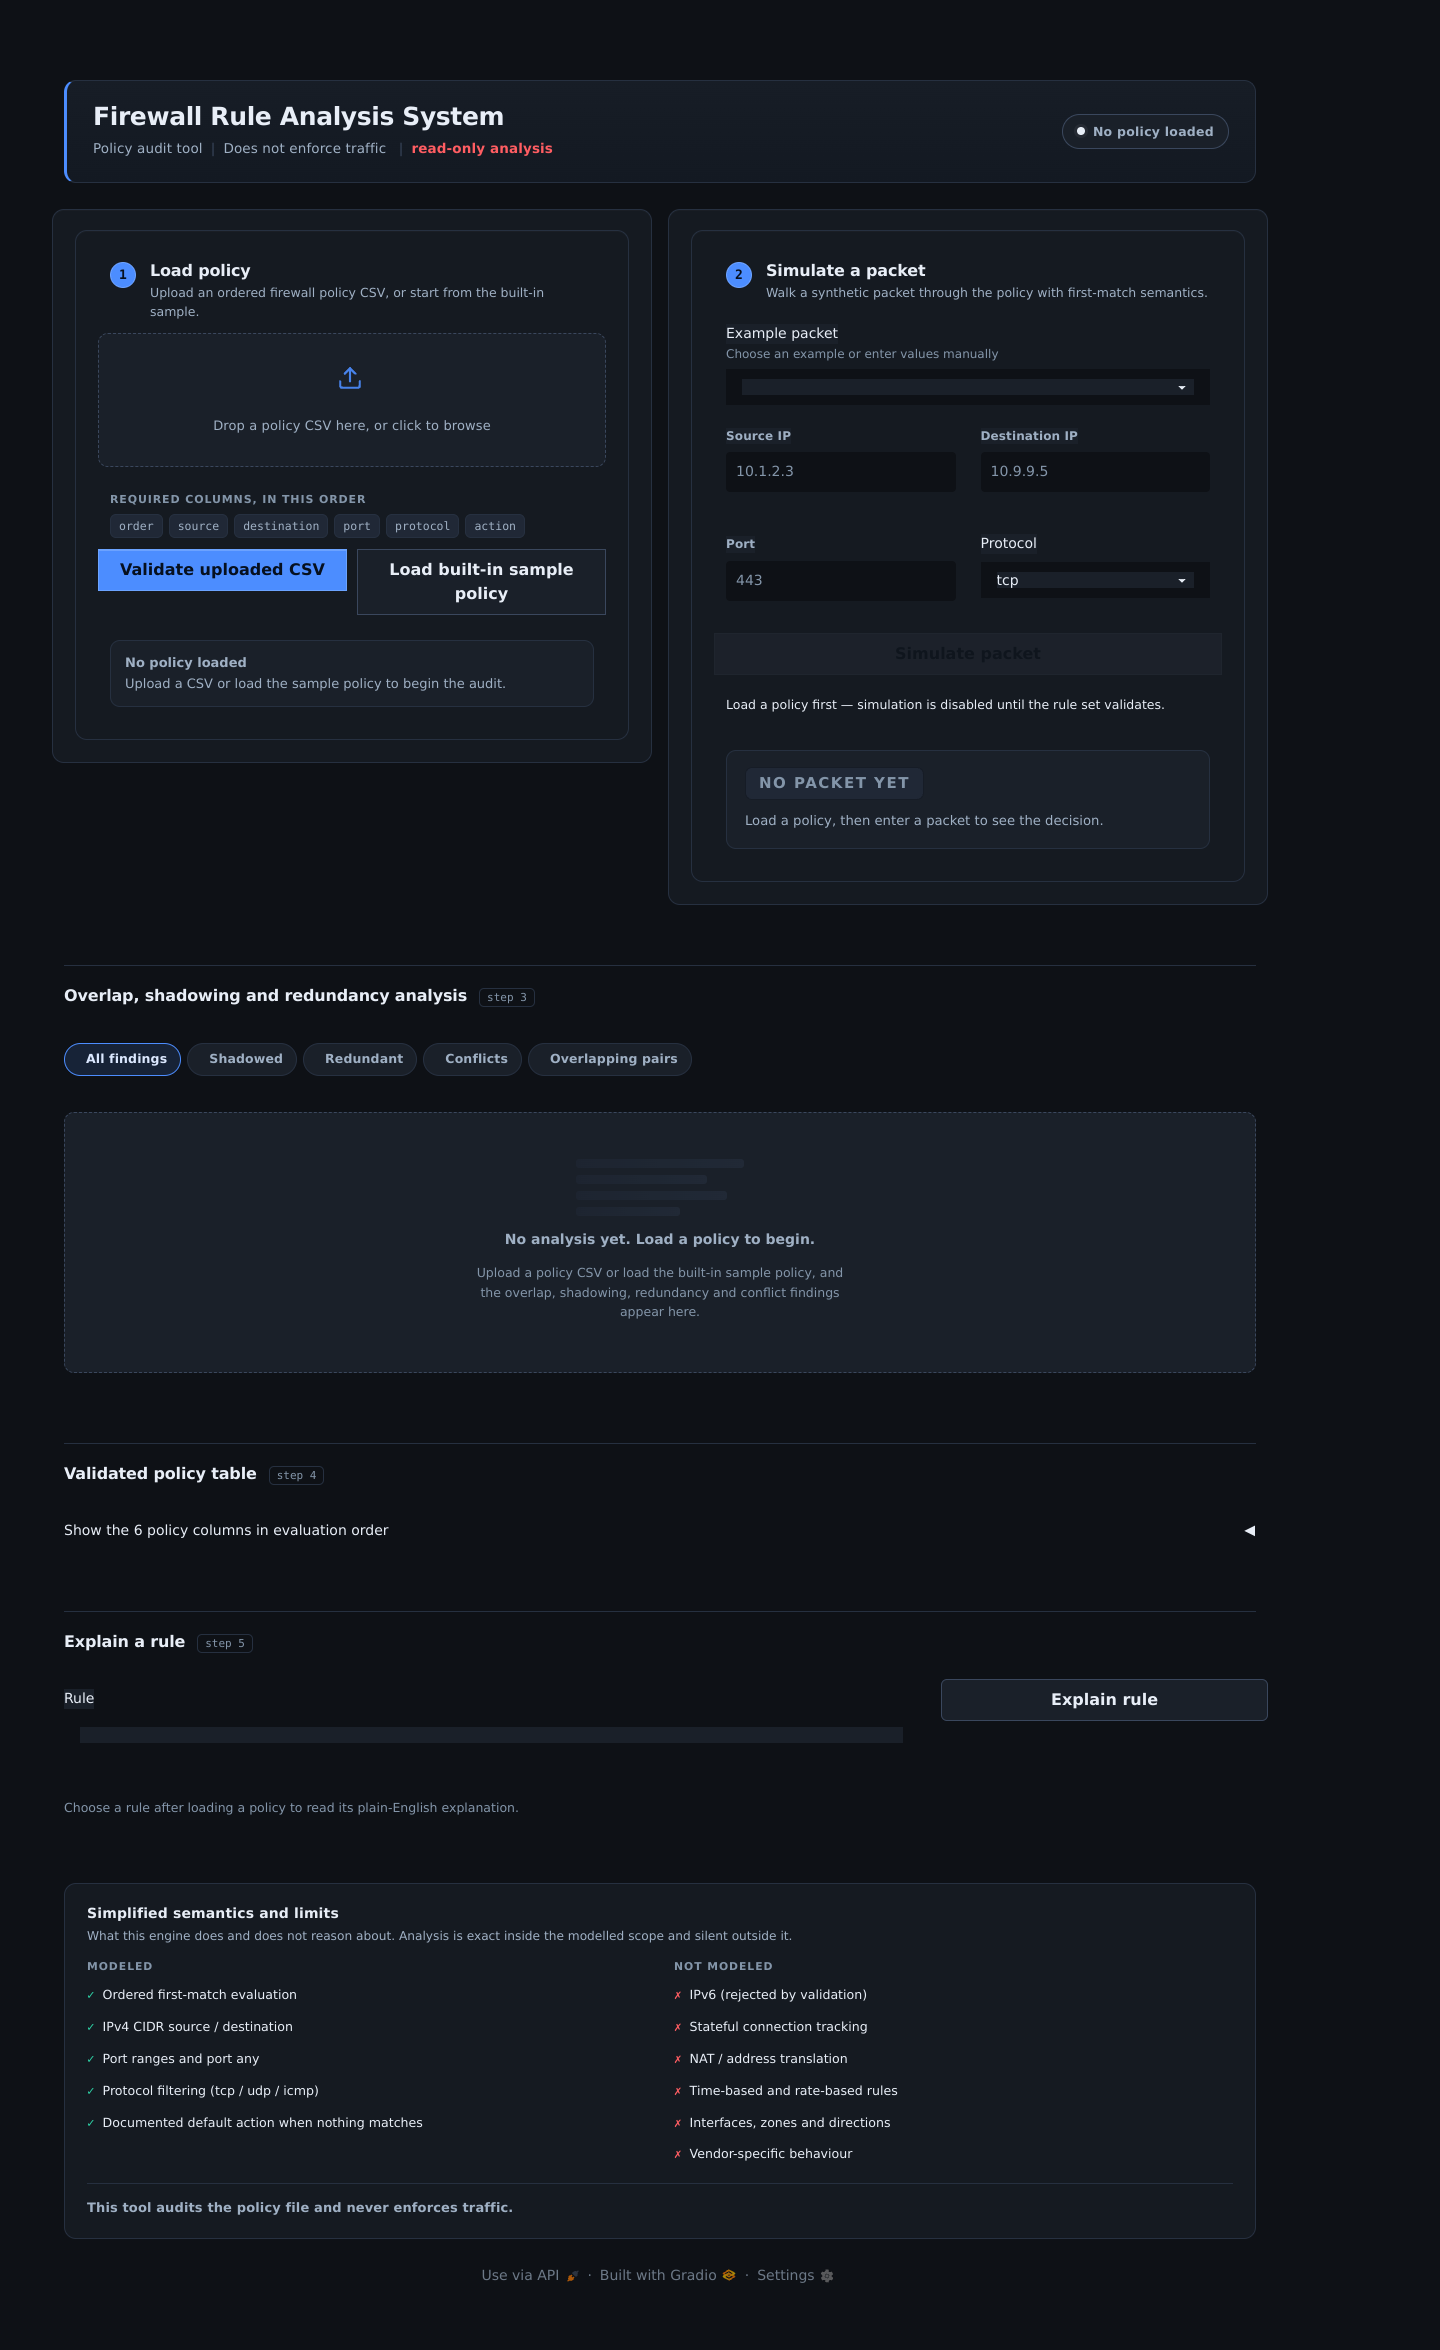

2 · Loaded with findings — green badge 'Policy loaded: 14 rules', segmented tabs with counts, category pills


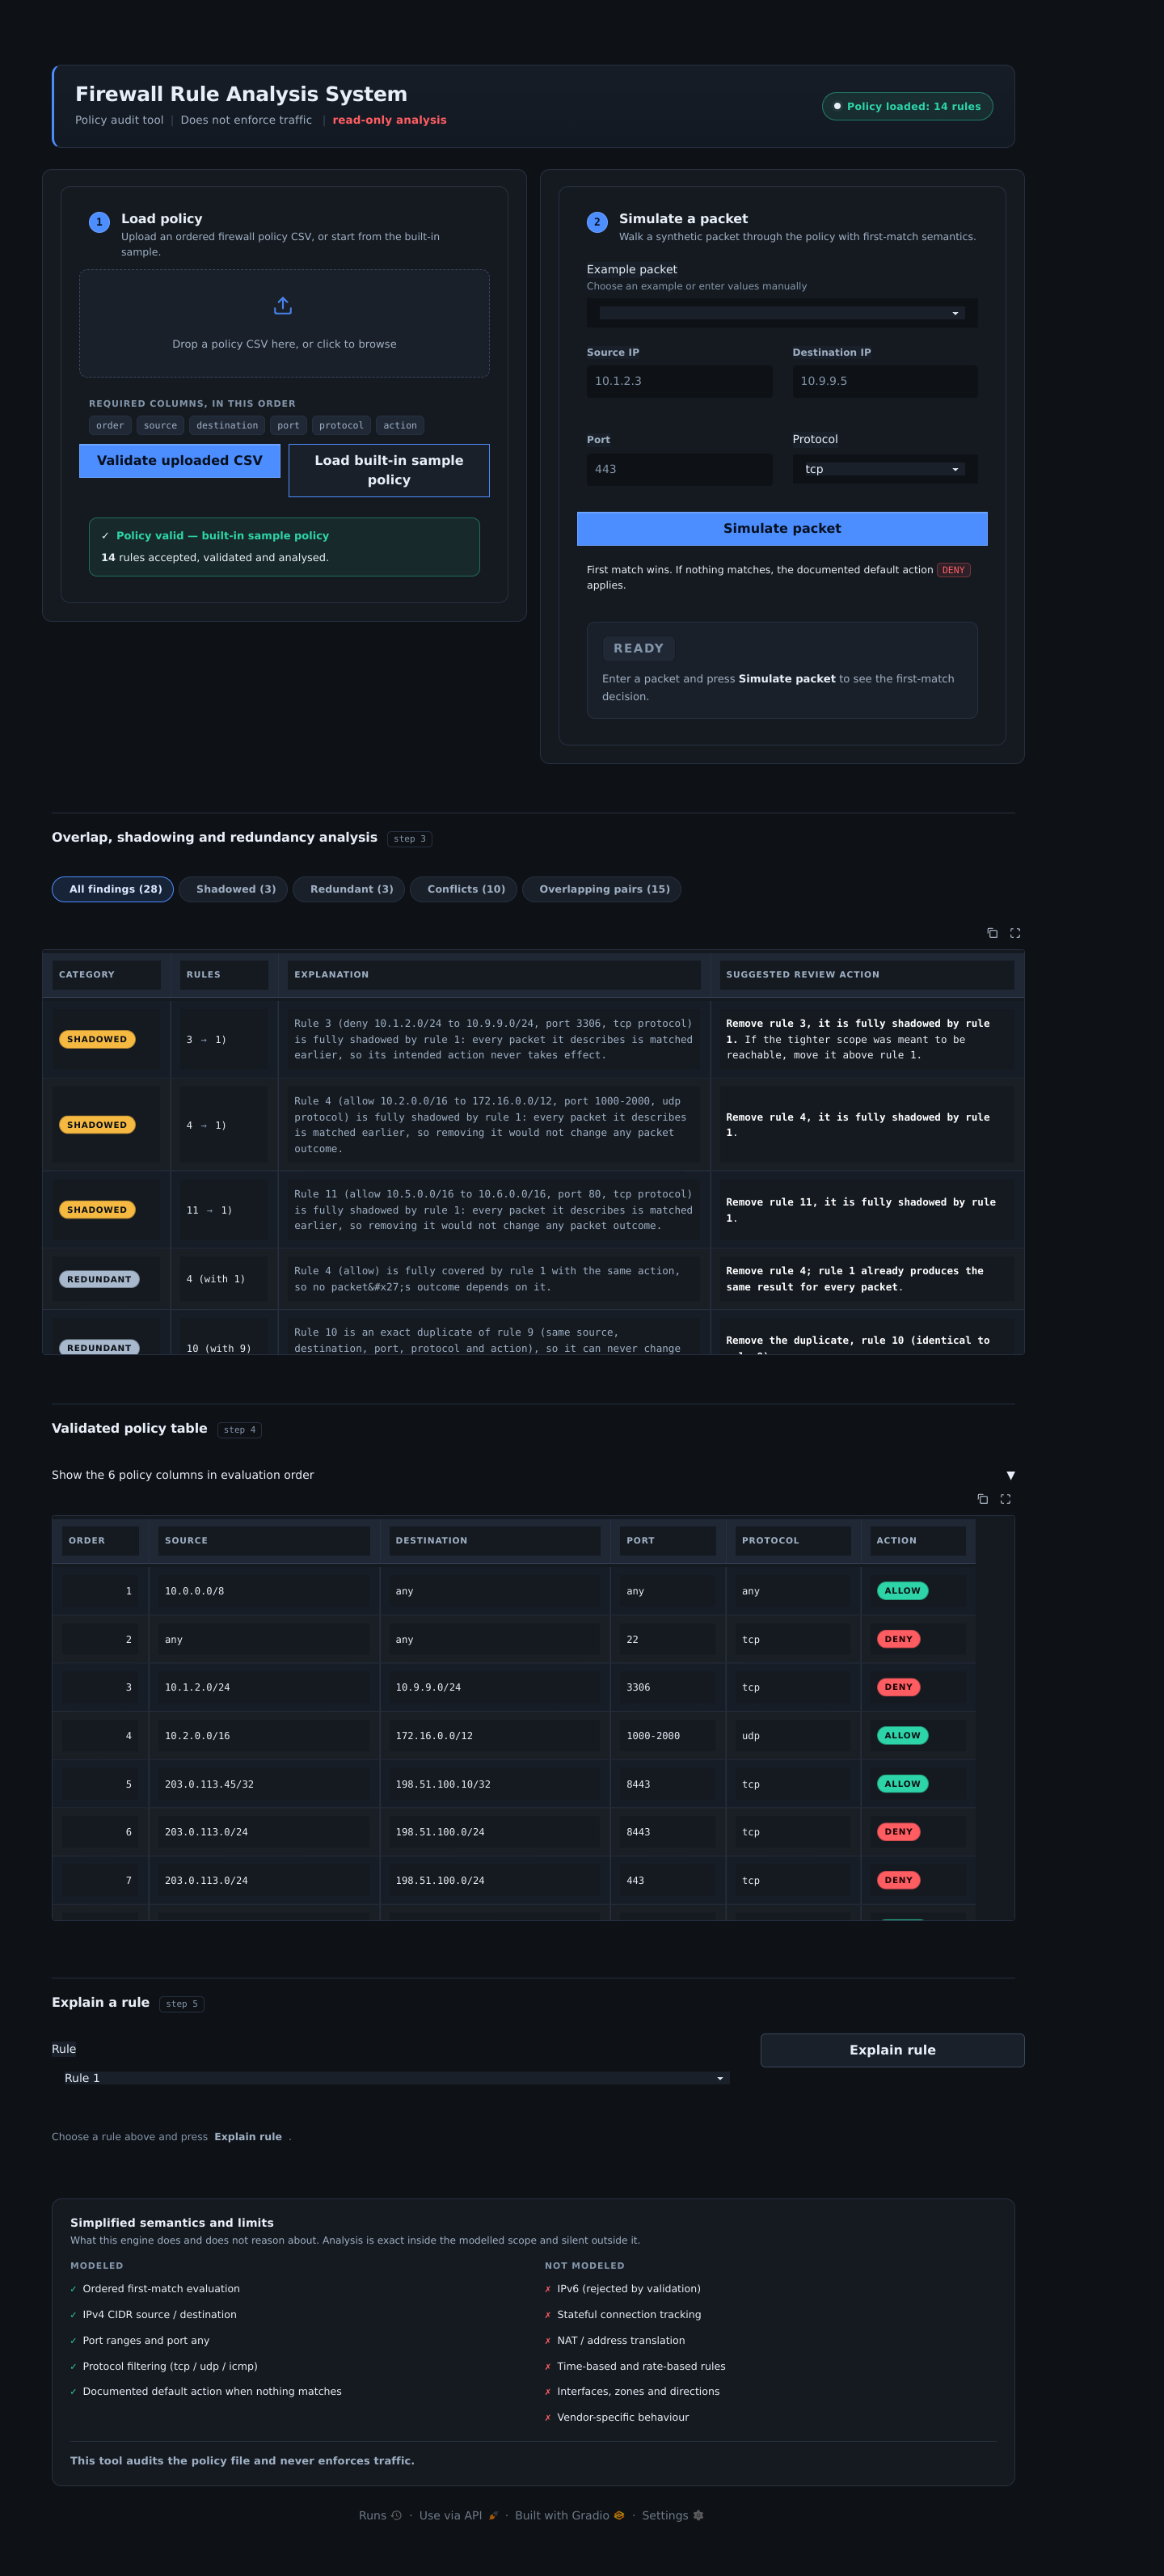

3 · Upload + validation error state — red badge 'Validation errors: 8', every row listed with a monospace row number


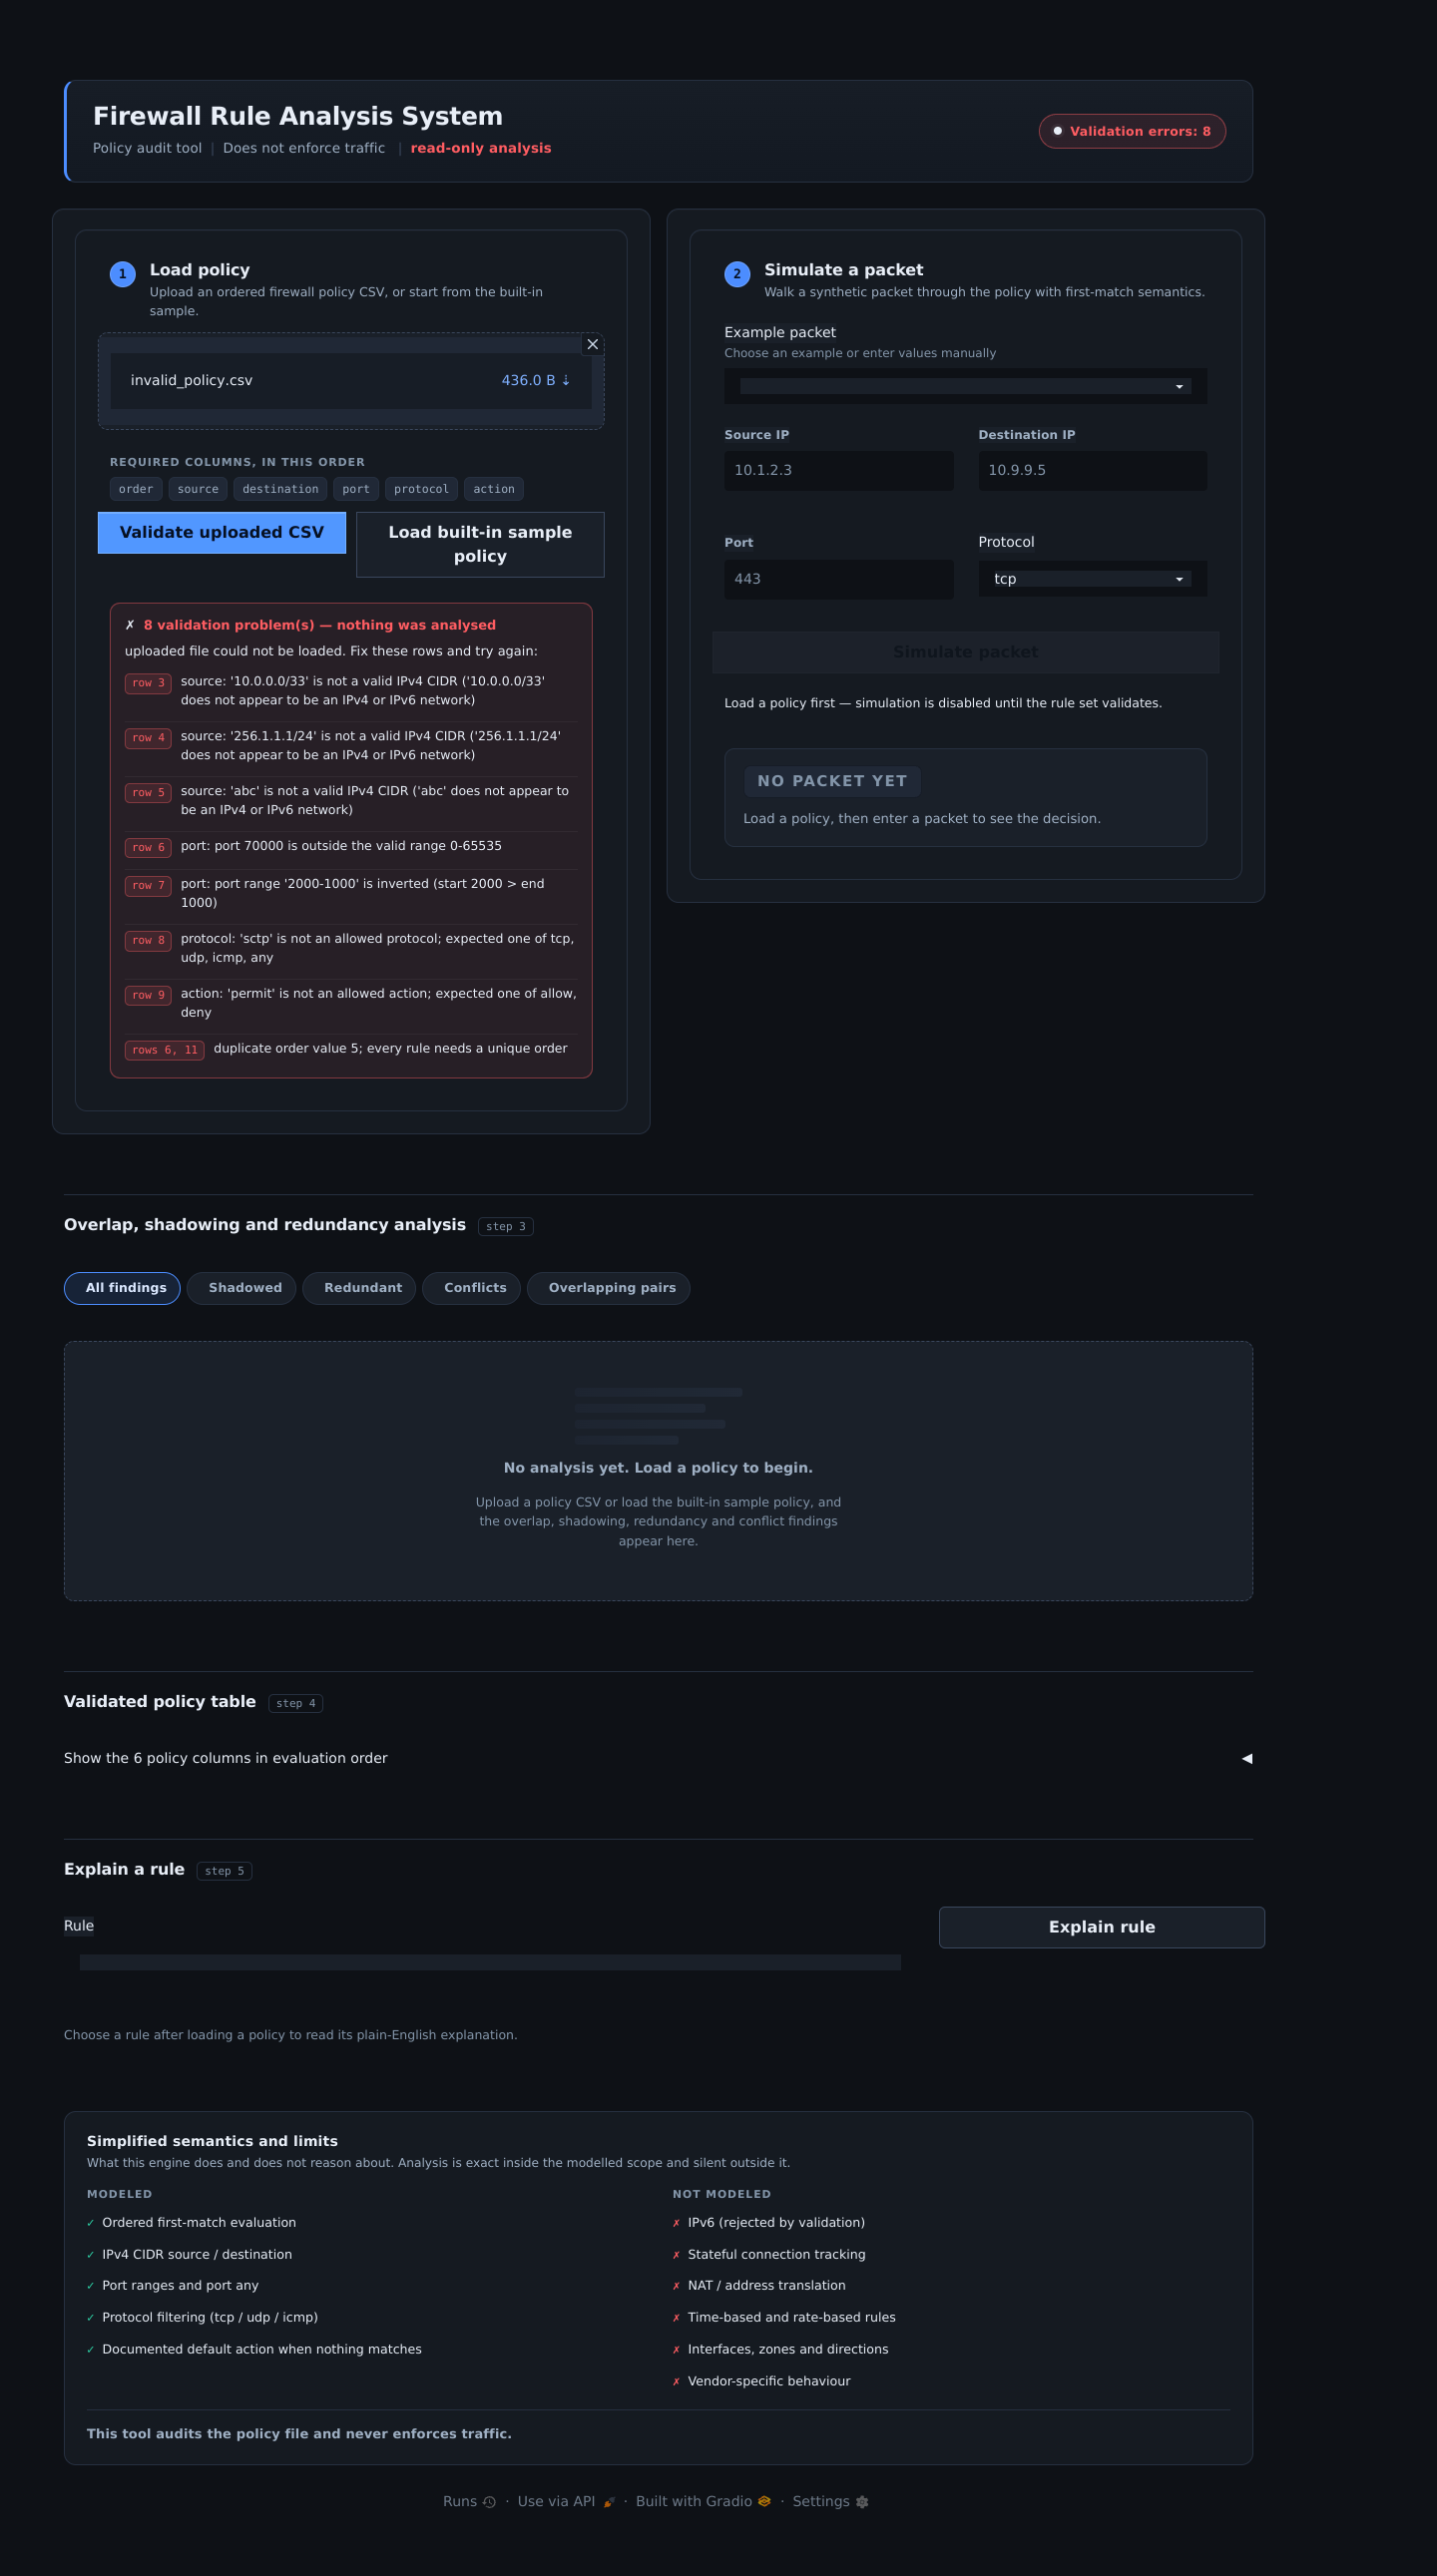

4 · Simulated packet — ALLOW, matched-rule chip 'Rule 1', explanation


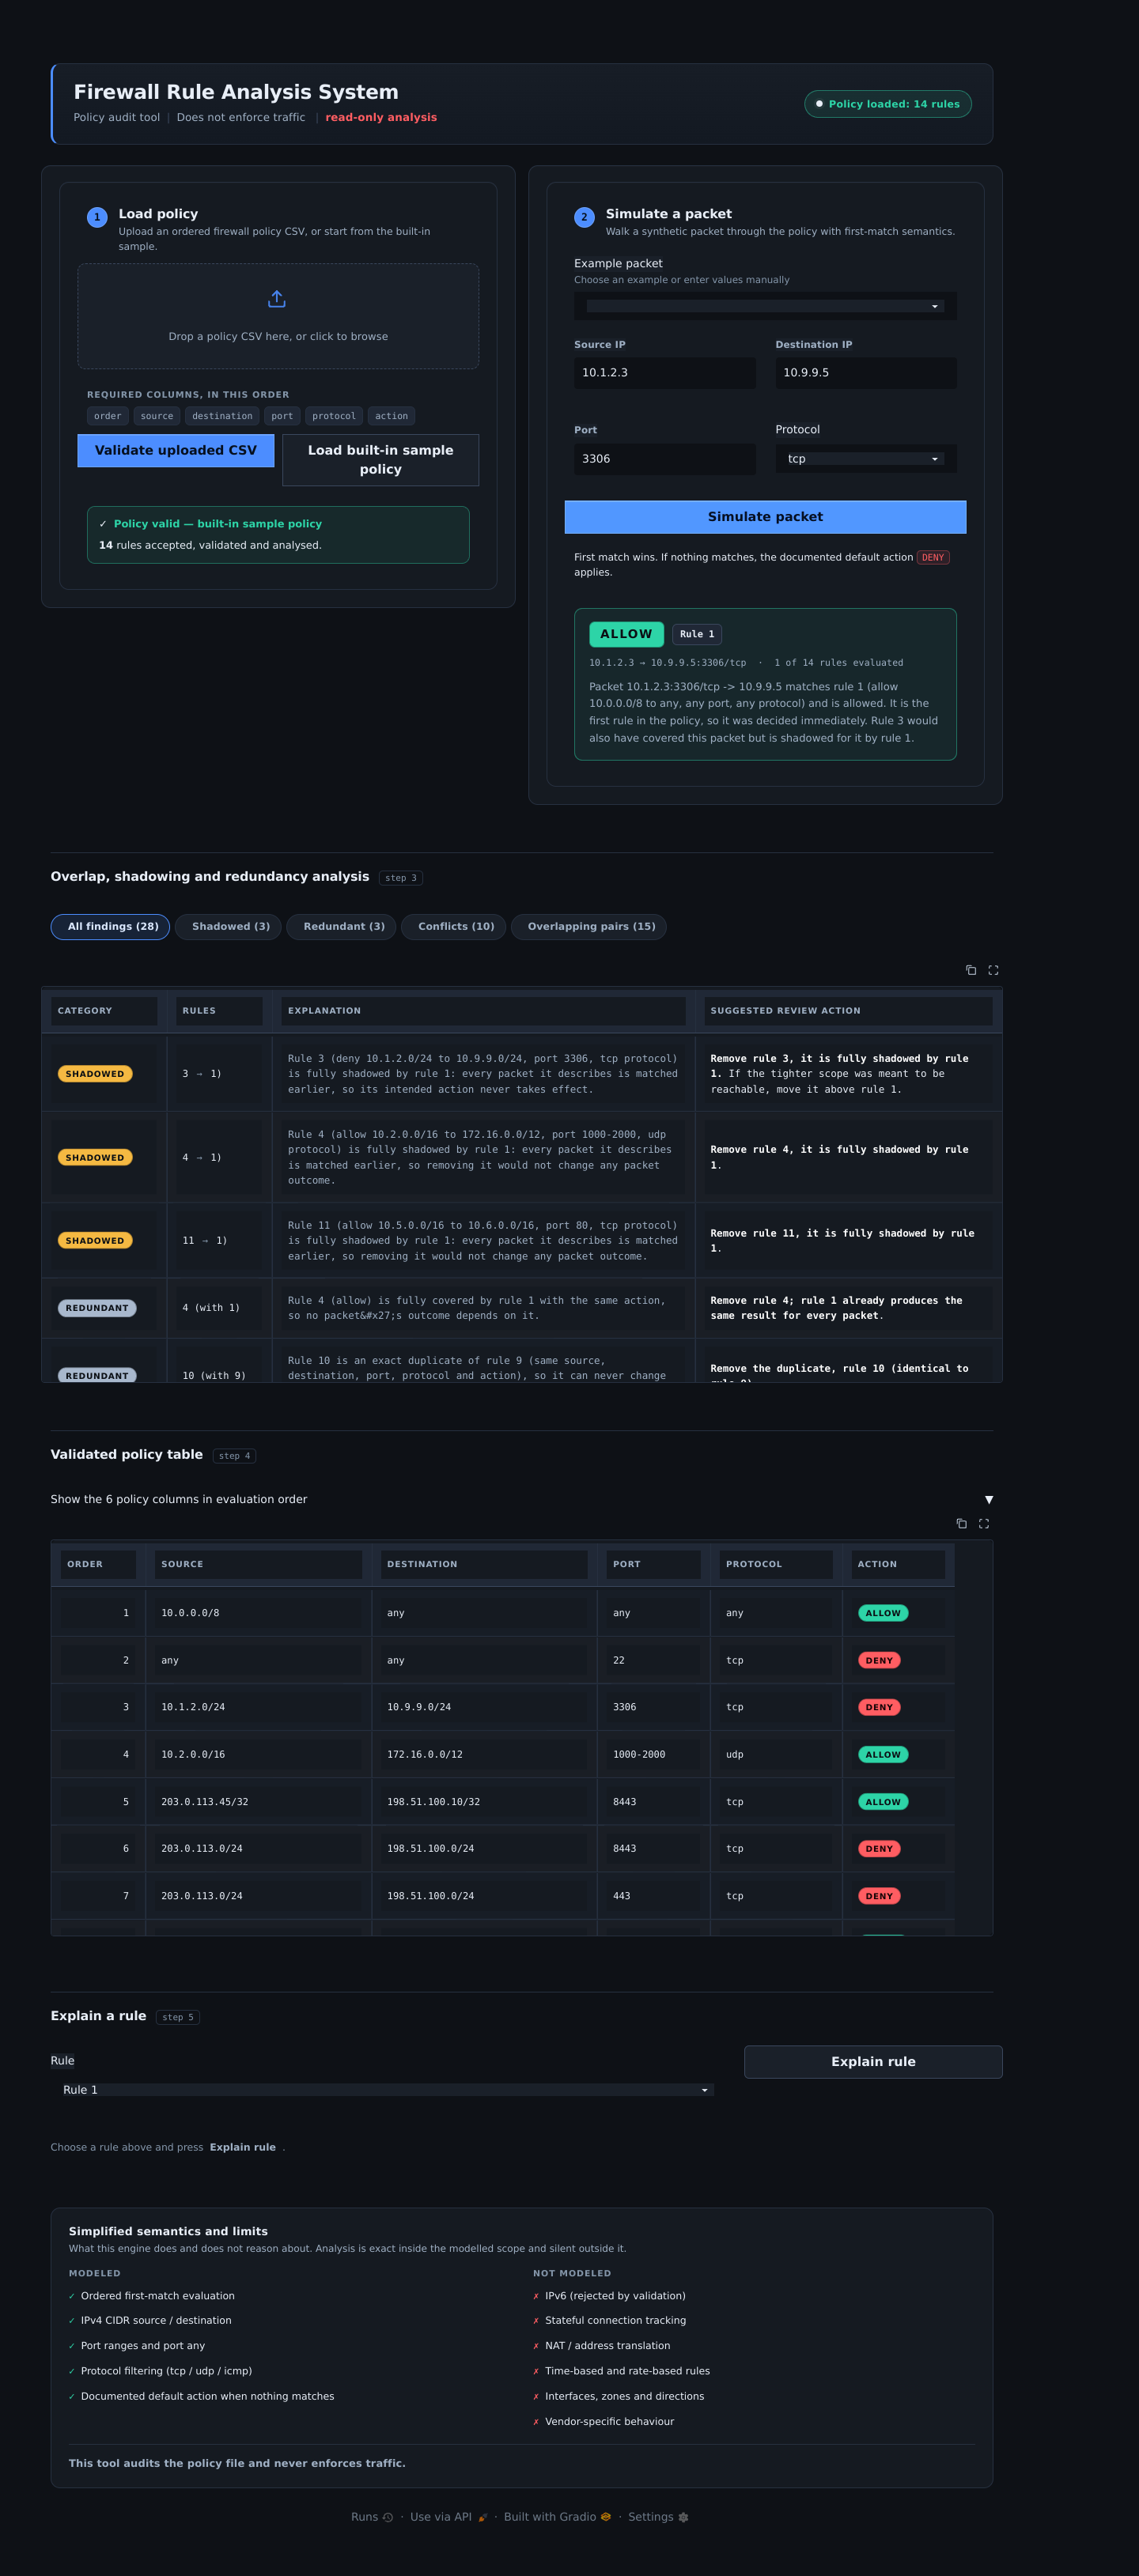

5 · Simulated packet — DENY, matched-rule chip 'Rule 7' (deny before allow)


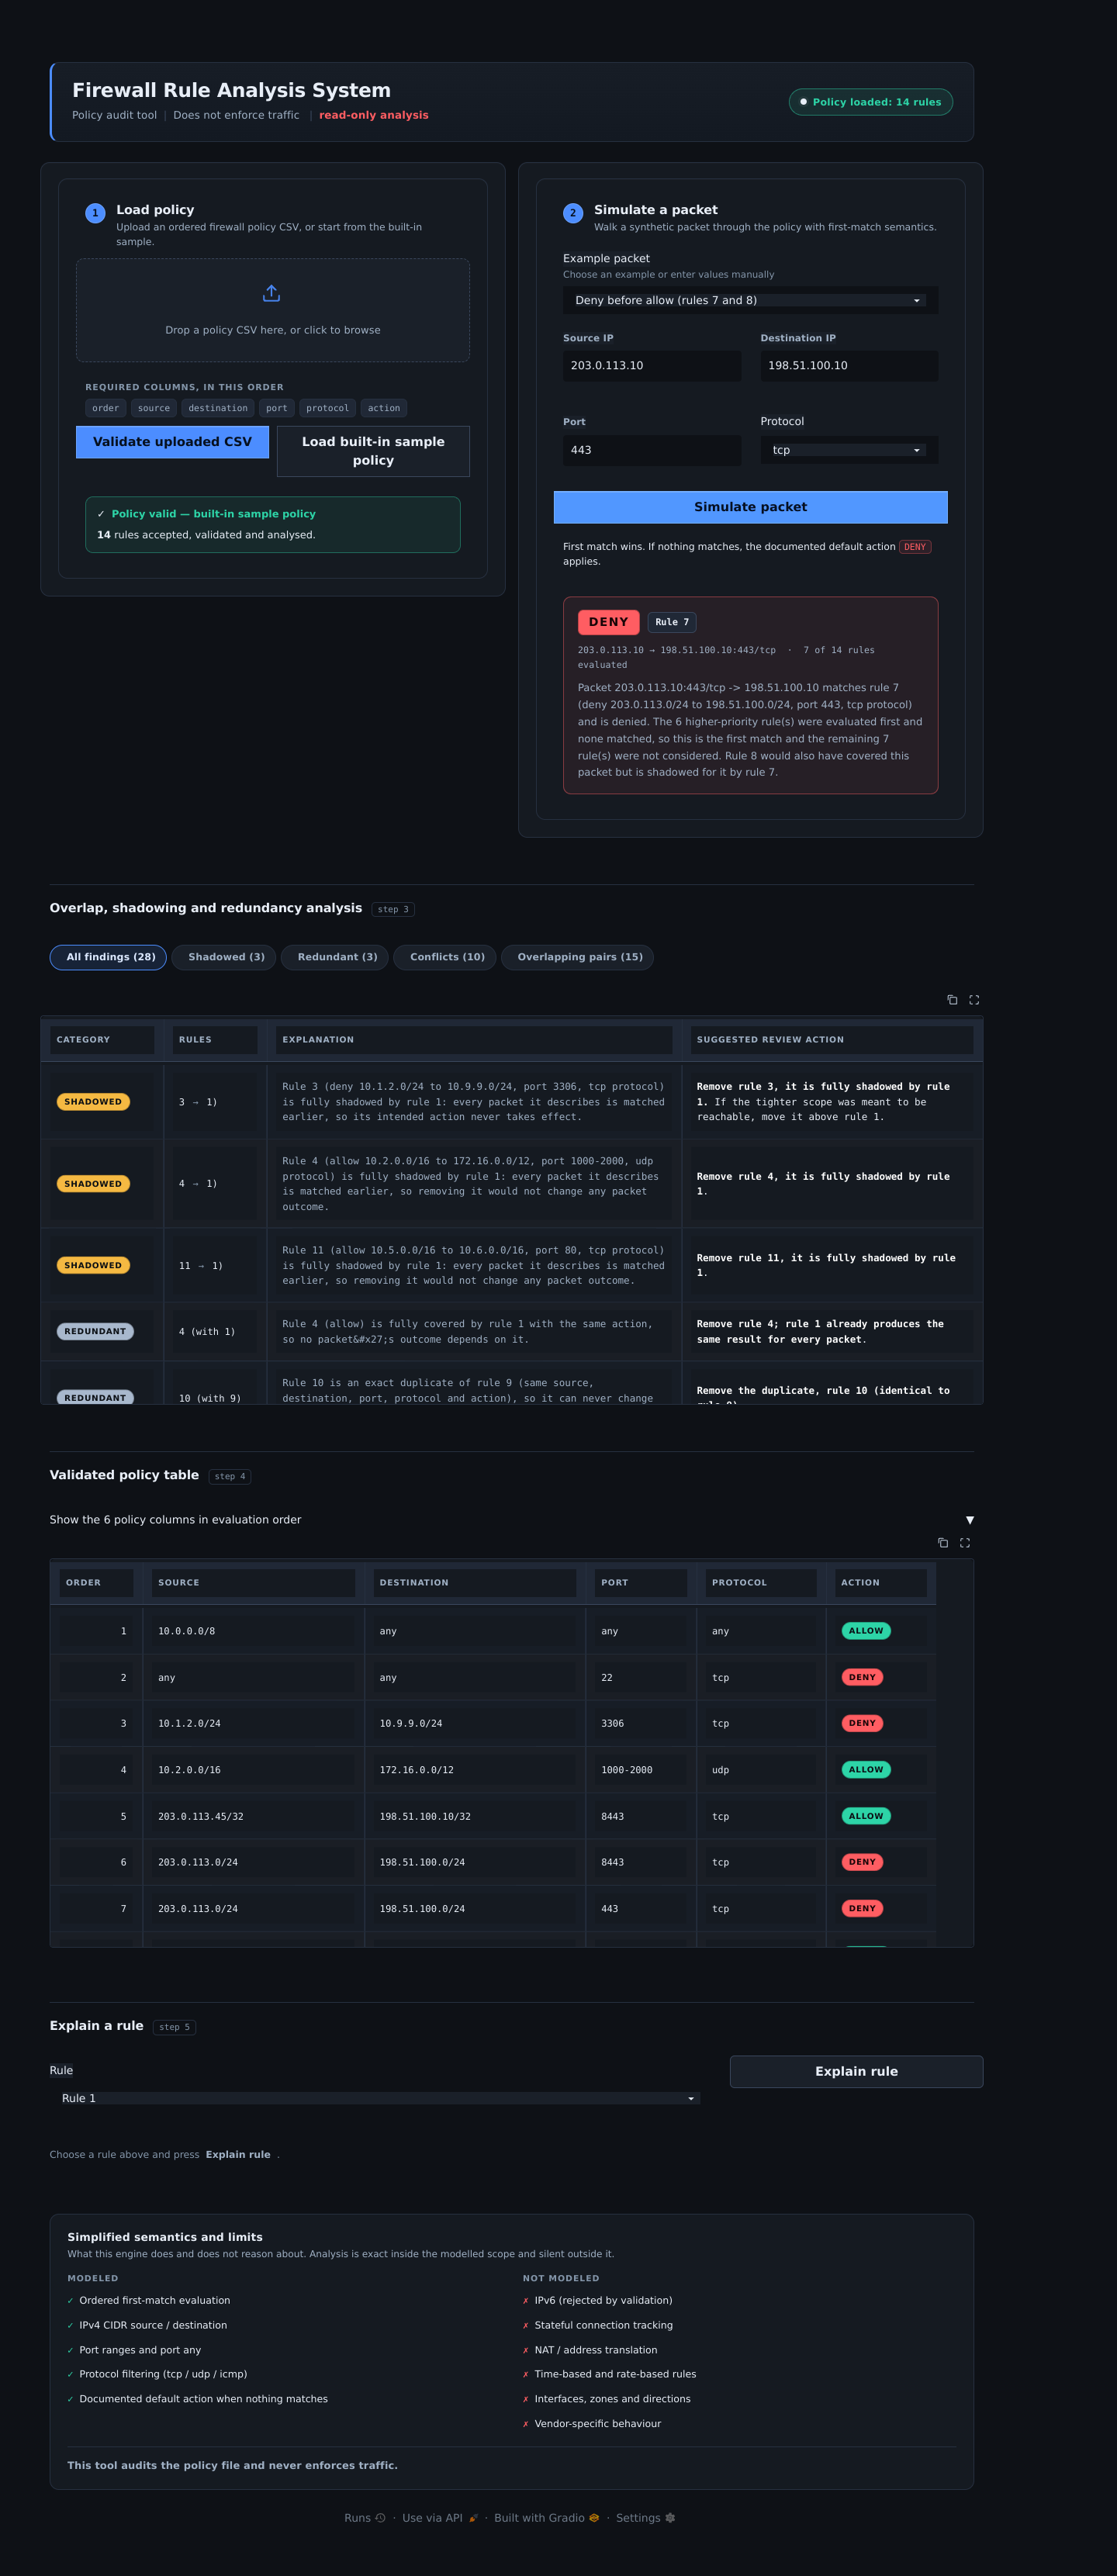

6 · Simulated packet — NO MATCH, DEFAULT DENY


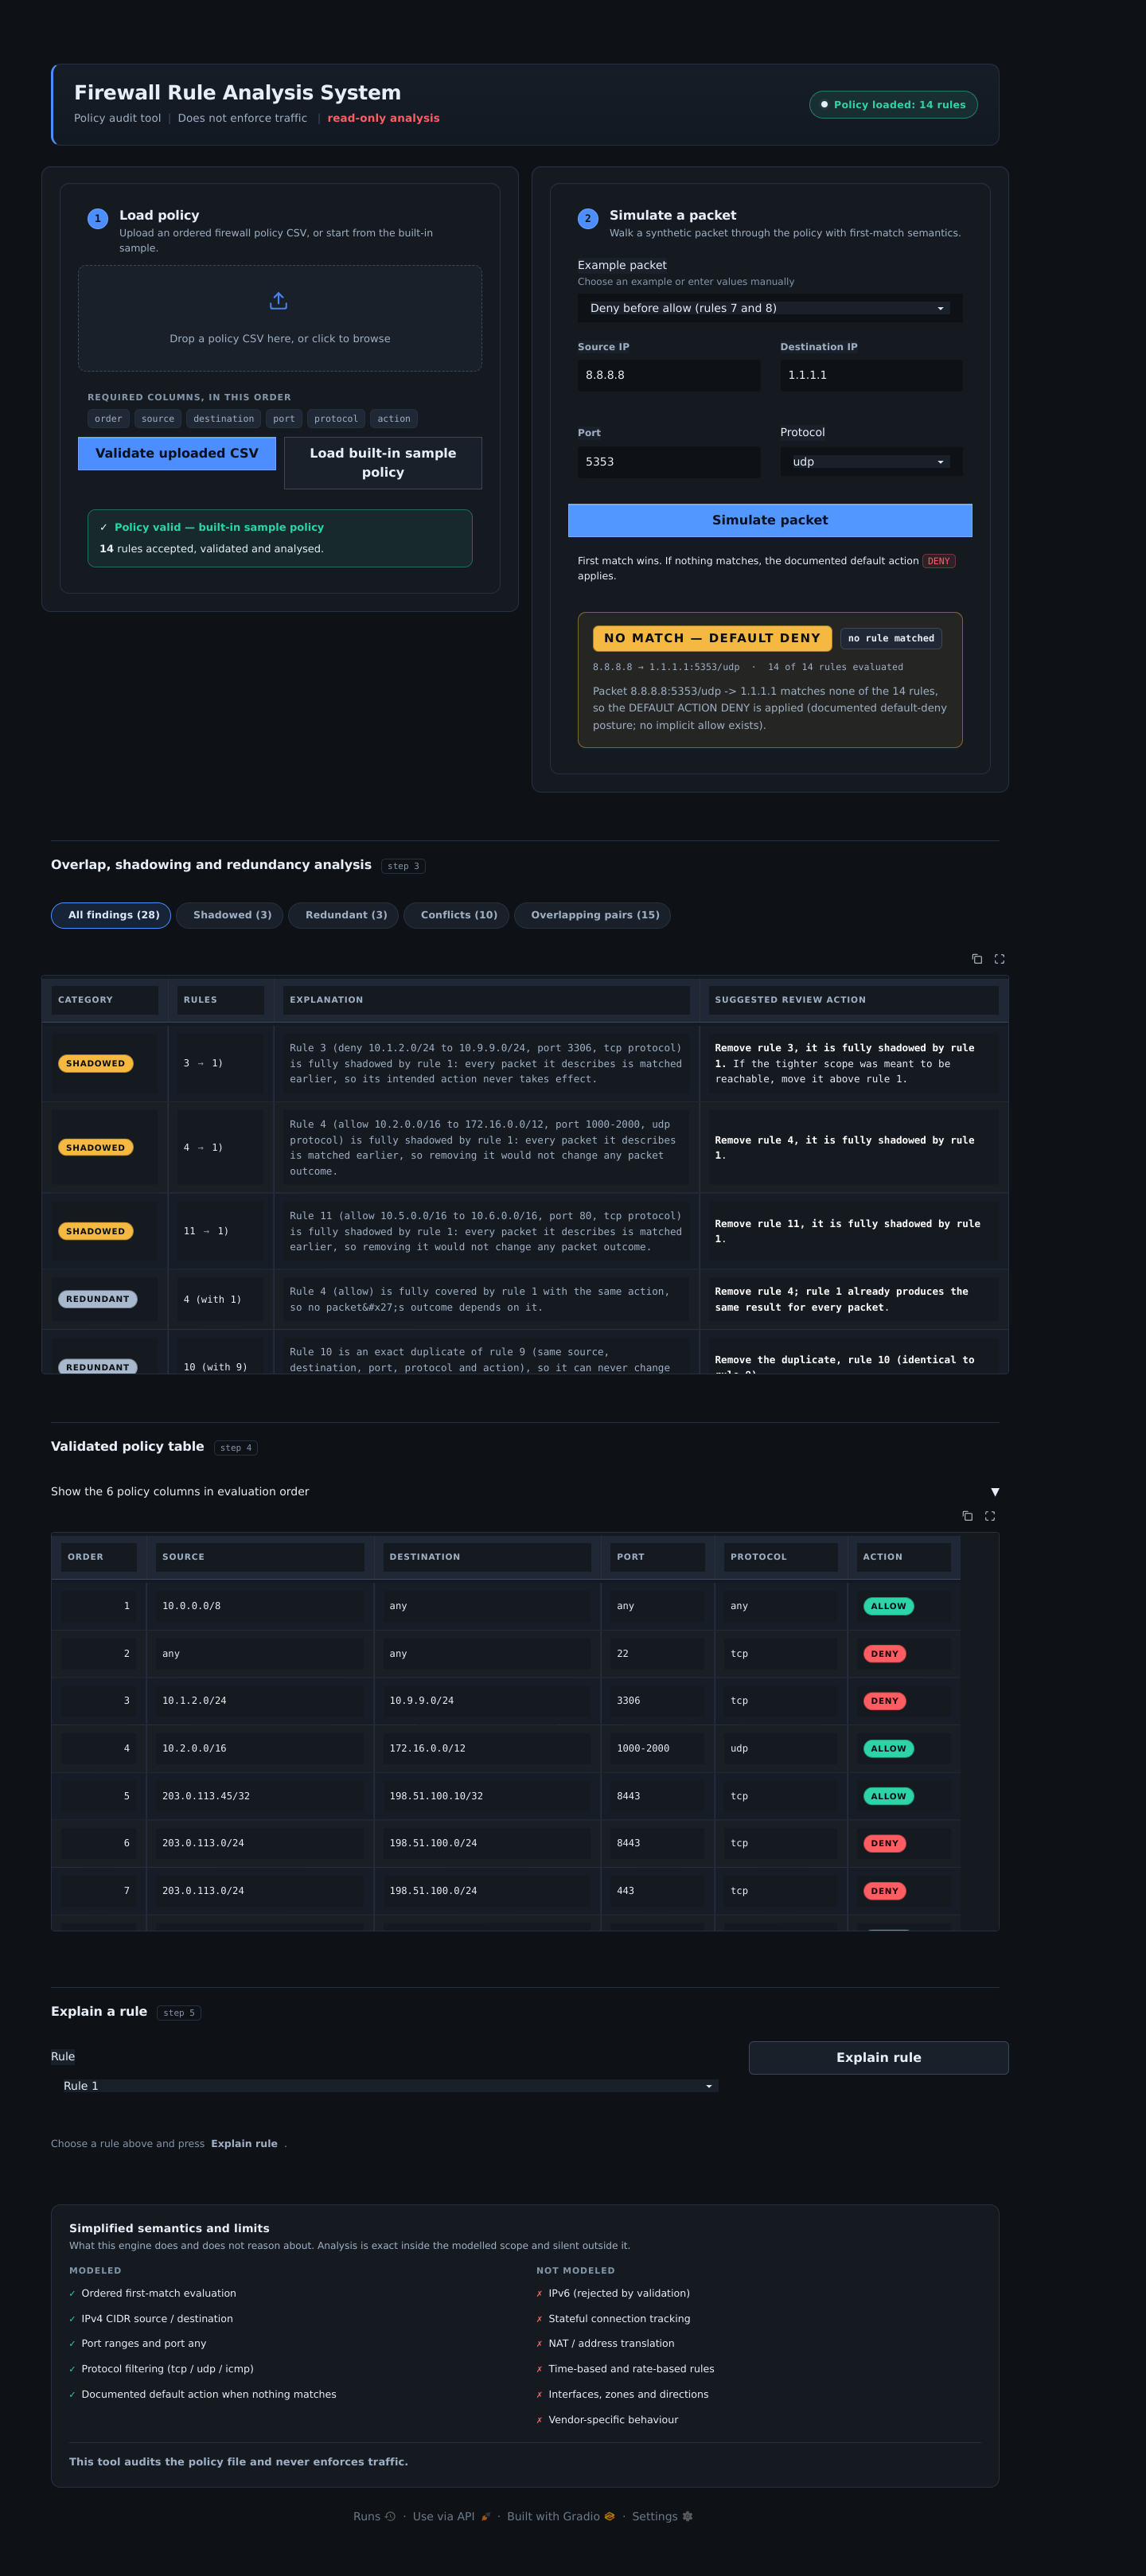

7 · Policy explanation — rule 3 in the quoted callout


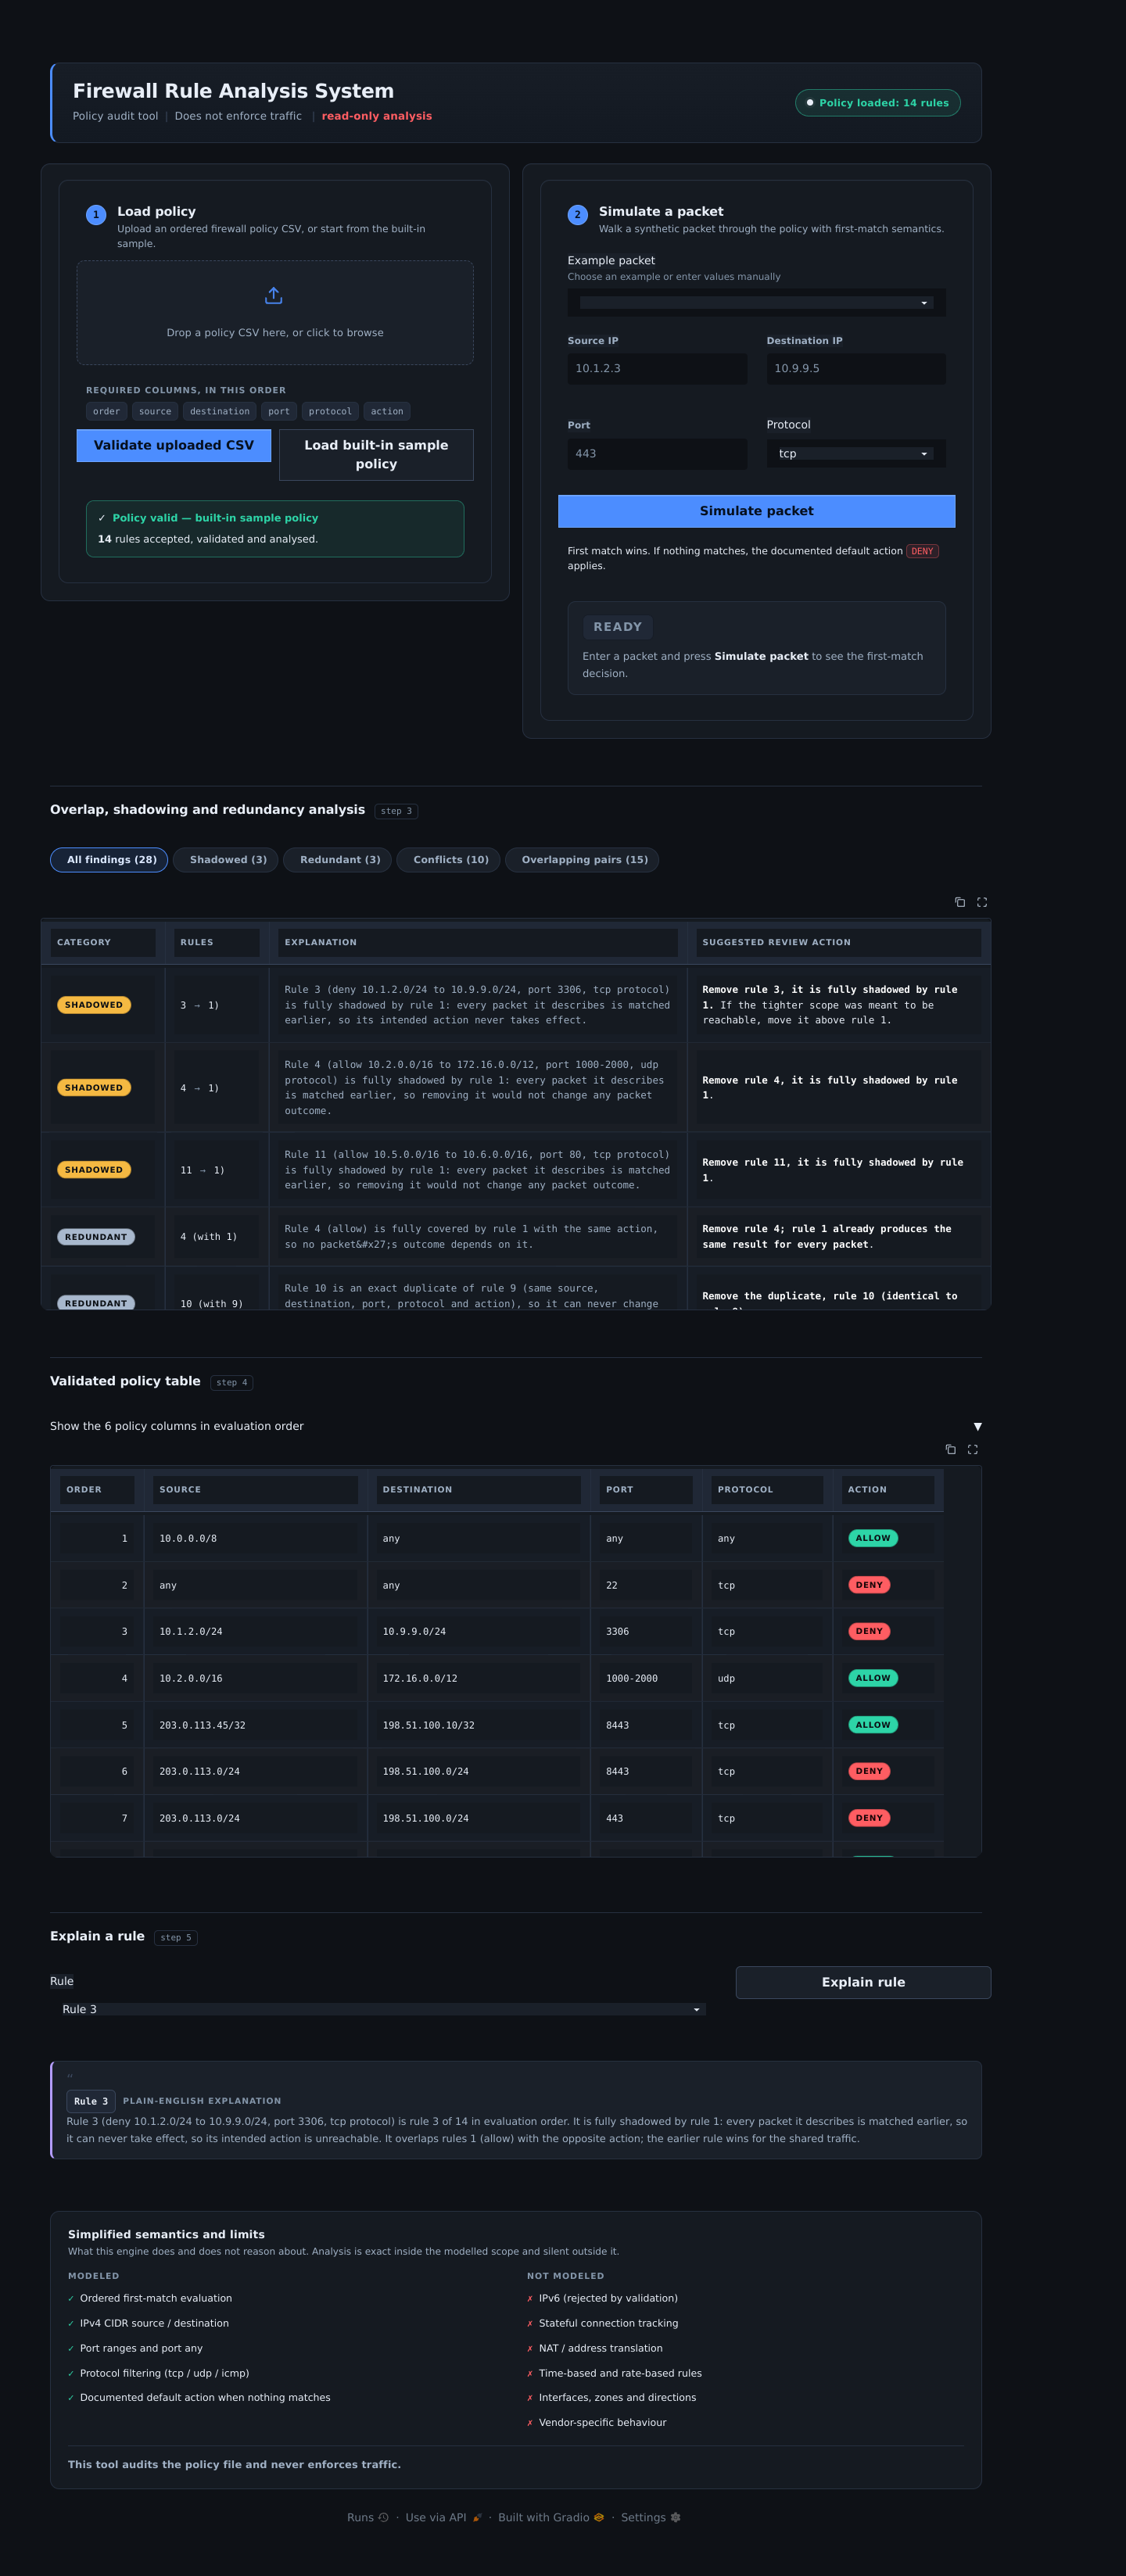

8 · Step 4 policy table — monospace scope columns with ALLOW/DENY pills


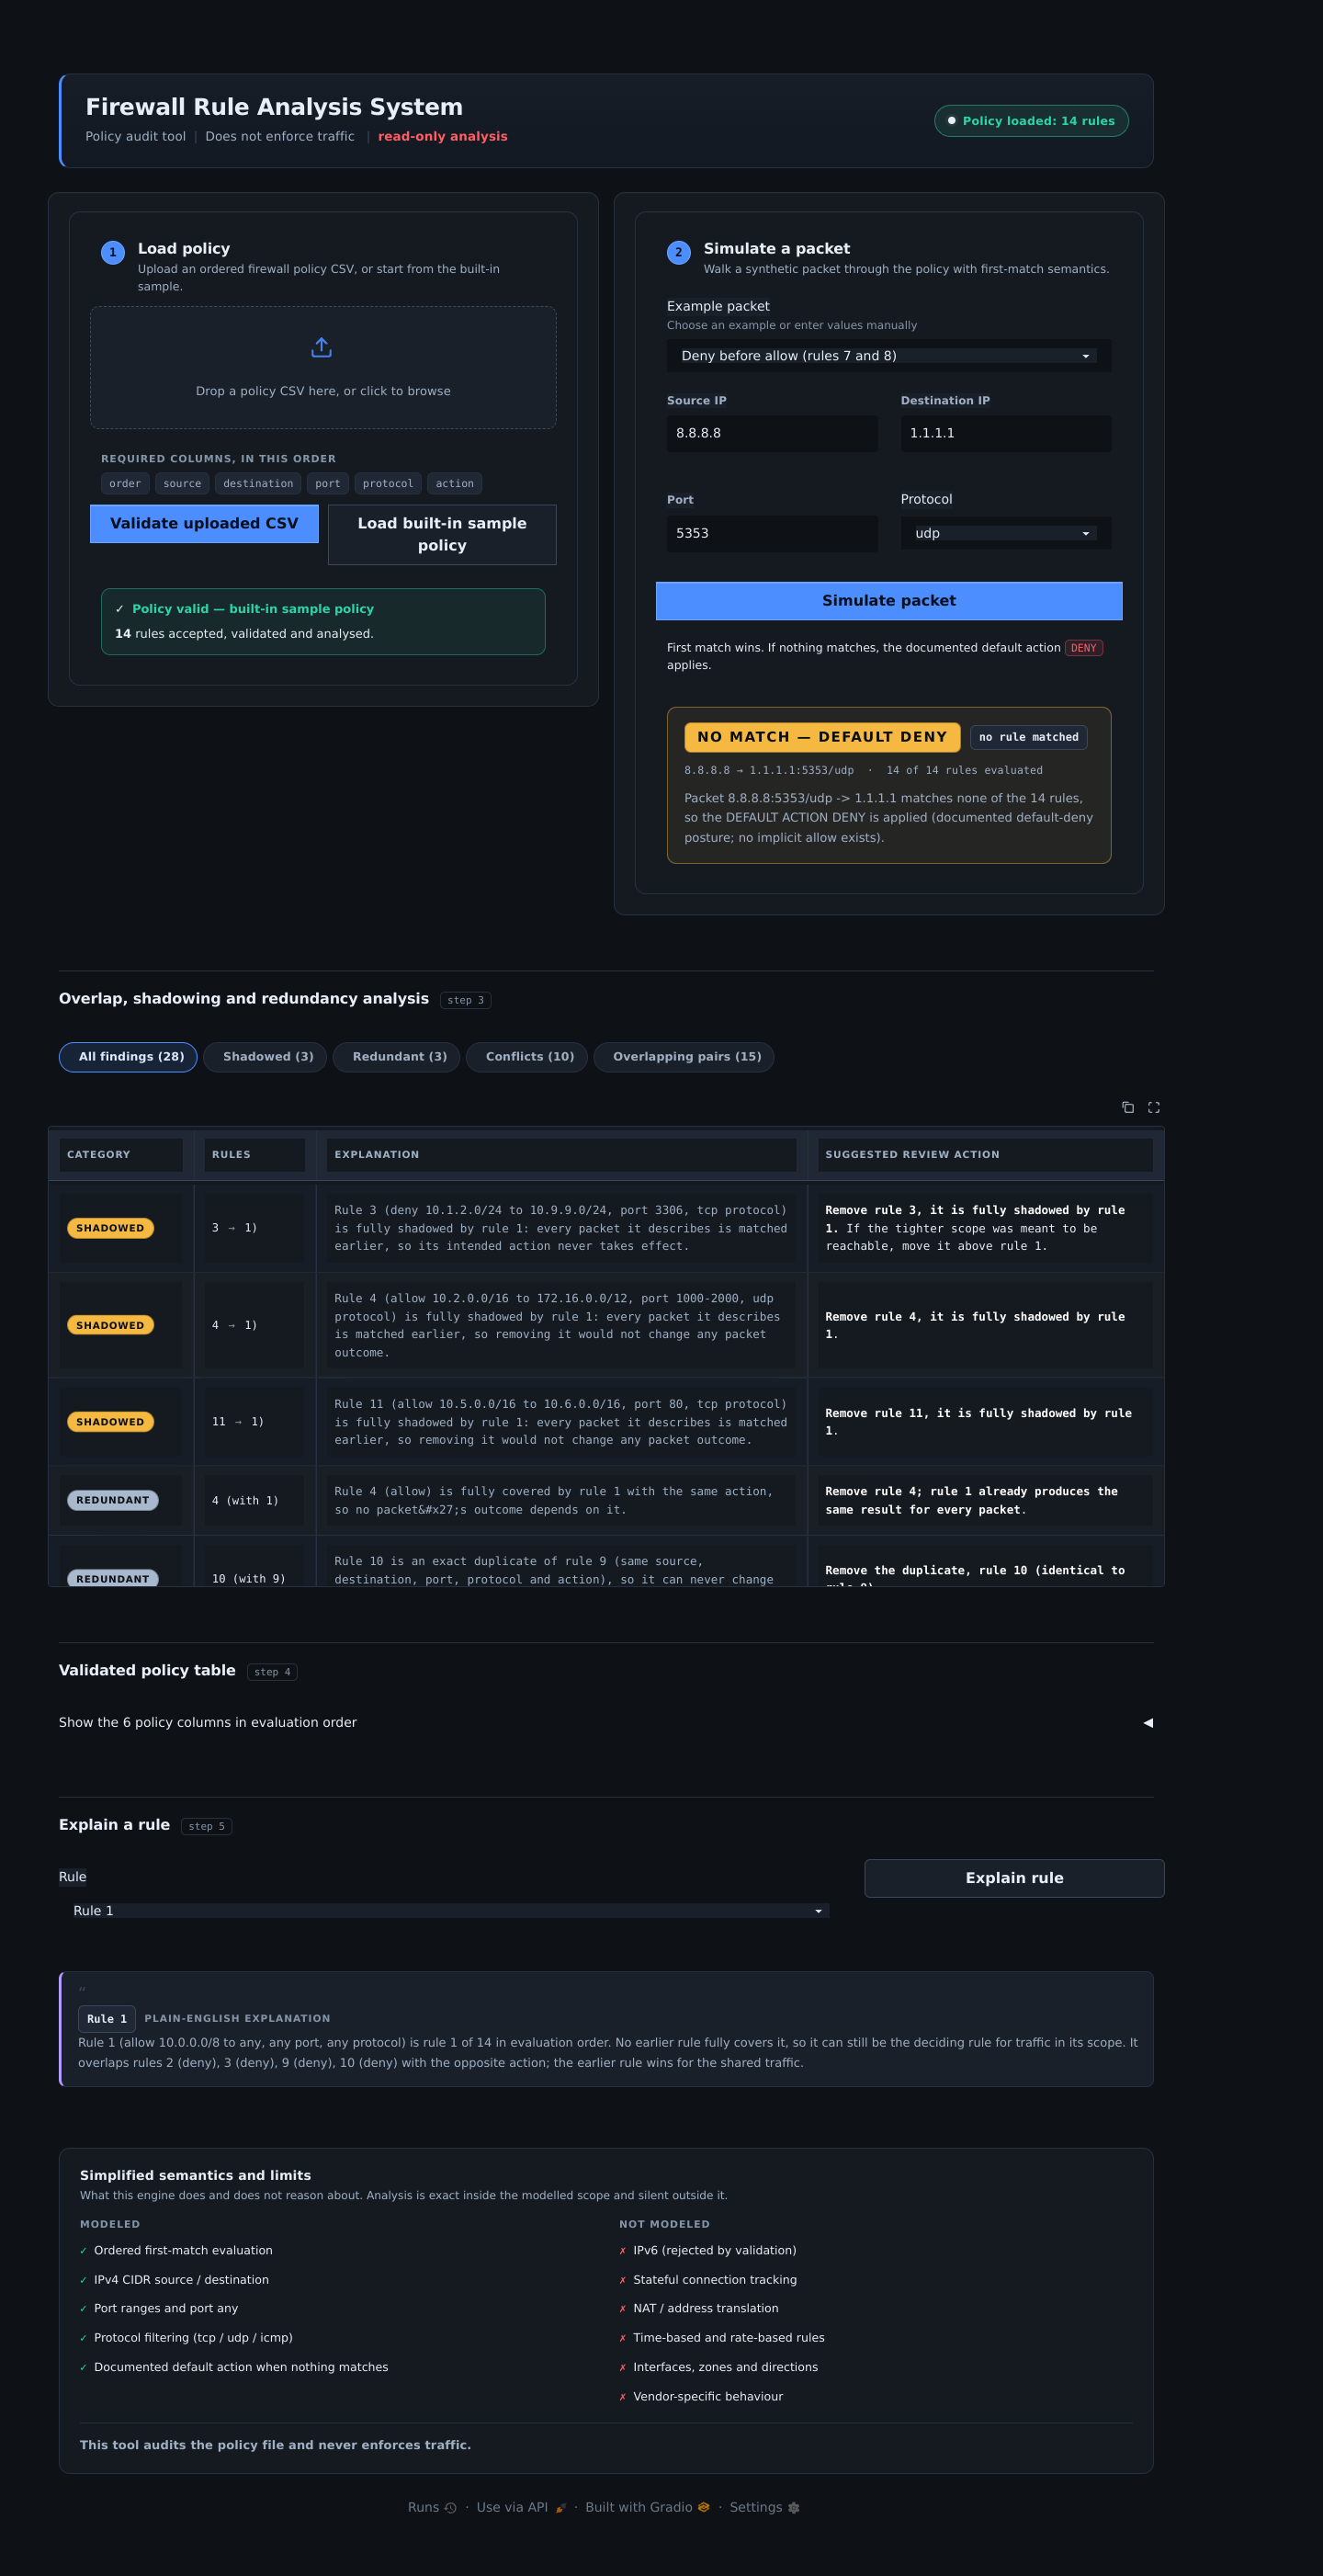

In [11]:
# ── 3.2 The captured screens (docs/screenshots) ──────────────────────────────
# Real captures from the running app, not mock-ups. See docs/SCREENSHOTS.md.
from IPython.display import Image

CAPTIONS = [
    ("01_empty_state.png",       "1 · Empty state — status badge 'No policy loaded', disabled simulator, no-analysis placeholder"),
    ("03_loaded_findings.png",   "2 · Loaded with findings — green badge 'Policy loaded: 14 rules', segmented tabs with counts, category pills"),
    ("02_validation_errors.png", "3 · Upload + validation error state — red badge 'Validation errors: 8', every row listed with a monospace row number"),
    ("04_simulate_allow.png",    "4 · Simulated packet — ALLOW, matched-rule chip 'Rule 1', explanation"),
    ("05_simulate_deny.png",     "5 · Simulated packet — DENY, matched-rule chip 'Rule 7' (deny before allow)"),
    ("06_simulate_no_match.png", "6 · Simulated packet — NO MATCH, DEFAULT DENY"),
    ("07_rule_explanation.png",  "7 · Policy explanation — rule 3 in the quoted callout"),
    ("08_policy_table.png",      "8 · Step 4 policy table — monospace scope columns with ALLOW/DENY pills"),
]

for filename, caption in CAPTIONS:
    path = pathlib.Path("docs/screenshots") / filename
    if path.exists():
        print(caption)
        display(Image(filename=str(path), width=900))
    else:
        print(f"[missing] {path}")

### 3.3 What the UI deliberately does *not* do

* It does not re-implement matching, overlap or shadowing logic.
* It does not modify the policy — the table and the findings are read-only.
* It does not persist anything, and it does not leave a server running unless
  you explicitly launch it.

<a id="4"></a>
## 4 · Acceptance tests

Eighteen `unittest` cases. The eight required acceptance tests map to T01-T08;
T09-T18 cover the validation and robustness rules the brief also demands.

| Requirement | Test |
|---|---|
| allow-before-deny: the allow above the overlapping deny wins | T01 |
| deny-before-allow: the reverse order gives the opposite outcome | T02 |
| wildcard scopes: `0.0.0.0/0` and `any` port/protocol match | T03 |
| invalid CIDR rejected with a clear error | T04 |
| shadowing: a fully covered later rule is flagged | T05 |
| redundancy: a duplicate rule is flagged | T06 |
| first-match: the first matching rule is returned, not a later one | T07 |
| no-match: the documented default action is applied | T08 |
| ports out of range / inverted / non-numeric | T09 |
| protocol and action outside the allowed values | T10 |
| duplicate and non-integer order values | T11 |
| missing column header | T12 |
| empty / non-CSV / Excel uploads | T13 |
| overlap detection finds intersecting pairs only | T14 |
| conflicts name the earlier rule as the winner | T15 |
| simulator input validation (CIDR as IP, port 99999, protocol any) | T16 |
| normalisation: sorted by order, lowercased, CIDR masked | T17 |
| end-to-end pipeline feeding the UI tables | T18 |

In [12]:
# ── 4.1 Run the suite (unittest, no mocks) ───────────────────────────────────
import unittest
import importlib
import firewall_rules.test_report as test_report

importlib.reload(test_report)                 # pick up edits without a restart
suite = unittest.defaultTestLoader.discover("tests", top_level_dir=".")
runner = unittest.TextTestRunner(verbosity=2, stream=sys.stdout)
outcome = runner.run(suite)

print(f"\nran {outcome.testsRun} tests · failures {len(outcome.failures)} · "
      f"errors {len(outcome.errors)}")
assert outcome.wasSuccessful(), "acceptance suite failed — see the output above"
print("ALL ACCEPTANCE TESTS PASSED")

test_T01_allow_before_deny (tests.test_acceptance.AcceptanceTests.test_T01_allow_before_deny) ... 

ok


test_T02_deny_before_allow (tests.test_acceptance.AcceptanceTests.test_T02_deny_before_allow) ... 

ok


test_T03_wildcard_scopes (tests.test_acceptance.AcceptanceTests.test_T03_wildcard_scopes) ... 

...

ok


test_T18_end_to_end (tests.test_acceptance.AcceptanceTests.test_T18_end_to_end) ... 

ok


----------------------------------------------------------------------
Ran 18 tests in 0.101s

OK



ran 18 tests · failures 0 · errors 0
ALL ACCEPTANCE TESTS PASSED


In [13]:
# ── 4.2 Test-case table, generated from the run above ────────────────────────
# "Actual result" is what each test observed; pass/fail comes from unittest.
from firewall_rules.test_report import run_acceptance_suite, test_case_rows

records = run_acceptance_suite()
passed = sum(1 for record in records.values() if record["status"] == "PASS")
print(f"{passed}/{len(records)} passed\n")

table = pd.DataFrame(test_case_rows()[1:], columns=test_case_rows()[0])
display(table)

markdown = test_report.markdown_table()
pathlib.Path("docs").mkdir(exist_ok=True)
pathlib.Path("docs/TEST_CASES.md").write_text(
    "# Test cases\n\nGenerated by `firewall_rules.test_report.markdown_table()`; "
    "the *actual result* column is what each test observed.\n\n" + markdown + "\n",
    encoding="utf-8",
)
print("written to docs/TEST_CASES.md")

18/18 passed



,Test ID,Description,Input,Expected result,Actual result,Pass/Fail
0,T01,Allow above an overlapping deny: the allow wins,Rule 1 allow 10.0.0.0/8 -> any 443/tcp; rule 2 deny any -> any 443/tcp. Packet 10.1.2.3 -> ...,"action = allow, matched rule 1","action = allow, matched rule 1",PASS
1,T02,Deny above an overlapping allow: the deny wins,Same two rules with the order swapped (deny first). Packet 10.1.2.3 -> 8.8.8.8:443/tcp,"action = deny, matched rule 1","action = deny, matched rule 1",PASS
2,T03,"Wildcard scopes 0.0.0.0/0, port any and protocol any match","Rule 0.0.0.0/0 -> 0.0.0.0/0, port any, protocol any, allow. Packets 8.8.8.8 -> 1.1.1.1:5353...",both packets match the rule and are allowed,udp/5353 -> allow rule 1; tcp/443 -> allow rule 1,PASS
3,T04,Invalid CIDR notation is rejected with a clear error,"Rows with source = 10.0.0.0/33, 256.1.1.1/24 and abc","3 errors naming rows 2, 3 and 4 with an IPv4 CIDR message",3 errors: row 2: source: '10.0.0.0/33' is not a valid IPv4 CIDR ('10.0.0.0/33' does not app...,PASS
4,T05,A fully covered later rule is flagged as shadowed,Built-in sample policy (rule 3 sits under rule 1),rule 3 reported shadowed by rule 1,"shadowed rules 3, 4, 11 (rule 3 by rule 1)",PASS
5,T06,A duplicate rule is flagged as redundant,Built-in sample policy (rule 10 duplicates rule 9),"rule 10 reported redundant, duplicate of rule 9","redundant rules 4 (covered), 10 (duplicate), 11 (covered)",PASS
6,T07,"The first matching rule is returned, not a later one",Rule 1 allow 10.0.0.0/8 443/tcp; rule 2 allow any 443/tcp. Packet 10.1.2.3 -> 8.8.8.8:443/tcp,matched rule 1 and only 1 rule evaluated,"matched rule 1, 1 rule(s) evaluated",PASS
7,T08,No match applies the documented default action,"Sample policy, packet 8.8.8.8 -> 1.1.1.1:5353/udp","action = deny (default), rule = None, is_default = True","action = deny (default), rule = None, is_default = True",PASS
8,T09,"Out-of-range, inverted and non-numeric ports are rejected","port = 70000, 2000-1000, abc",3 errors with range and malformed-range messages,3 errors: row 2: port: port 70000 is outside the valid range 0-65535 | row 3: port: port ra...,PASS
9,T10,Unknown protocol and action values are rejected,"protocol = sctp, action = permit",2 errors naming the allowed values,"row 2: protocol: 'sctp' is not an allowed protocol; expected one of tcp, udp, icmp, any | r...",PASS


written to docs/TEST_CASES.md


<a id="5"></a>
## 5 · Limitations

# Limitations

The Firewall Rule Analysis System audits a policy **file**. It does not enforce
traffic, does not connect to a device and does not observe real packets. Its
conclusions are only valid inside the simplified semantics below, all of which
are also documented in the engine's module docstring.

## 1. What the model ignores

* **Stateful connection tracking.** There is no `established` / `related`
  state. Every packet is evaluated as if it were the first packet of a flow, so
  return traffic needs its own rule. A policy that relies on a stateful engine
  to permit replies will look stricter here than it behaves in production, and
  a rule set that is only correct because of connection tracking will be
  reported as though it were not.
* **NAT.** No source or destination translation is modelled. Addresses are
  compared exactly as written, and pre-NAT / post-NAT address spaces are not
  distinguished. A finding about a `/32` host is about the address in the file,
  not about the address a packet will carry after translation.
* **Time-based rules.** No schedules, time windows, rate limits, quotas,
  session limits or counters. A rule that only applies between 09:00 and 17:00
  is treated as always active.
* **IPv6.** IPv4 only. IPv6 CIDRs are rejected by validation with an explicit
  message rather than being silently skipped, so an IPv6 policy fails loudly
  instead of producing an empty report.
* **Interface-specific behaviour.** The policy is single-interface. Zones,
  interfaces, directions (inbound / outbound / forward), VRFs, routing
  instances and per-interface defaults are not modelled: a rule is a filter on
  a (source, destination, port, protocol) tuple, not on a path through a
  device.
* **Application awareness.** No layer-7 inspection, user identity, application
  signatures, URL categories, TLS inspection or geolocation objects. A
  "destination" is an IPv4 range and nothing else.
* **Negation, groups and objects.** Rules are flat and independent. There are
  no `except` clauses, no negated addresses, no address/service groups, no
  inheritance, no implicit services and no vendor object expansion.

## 2. How the policy is interpreted

* **An ordered list with a single default action.** Rules are sorted by their
  `order` column and evaluated top to bottom; the first match wins and nothing
  after it is considered. When no rule matches, the documented default action
  applies: **deny** (`engine.DEFAULT_ACTION`). There is exactly one default for
  the whole policy — no per-zone or per-direction defaults, and no implicit
  allow anywhere.
* **A port dimension on every protocol.** Real ICMP has no ports. The engine
  evaluates the port field uniformly for all protocols so that overlap maths
  stays symmetric, so a rule with `protocol=icmp` and a specific port is
  interpreted literally. All ICMP rules in the sample policy use `port=any`.
* **Redundancy is single-rule.** A rule is flagged redundant only when an
  earlier rule *by itself* covers it (same action). A rule made redundant only
  by the union of several earlier rules (two `/25`s covering a later `/24`) is
  not reported. Shadowing and overlap detection are exact within the 4-tuple
  model.
* **Analysis is over the file, not over traffic.** Counts describe the rule set,
  not the network. "15 overlapping pairs" says nothing about how much traffic
  those pairs carry.

## 3. What it therefore cannot do

* **Model real vendor-specific firewall behaviour.** Policy formats, default
  actions, implicit rules, NAT interactions, stateful inspection, logging and
  hit counts differ between Cisco ASA/FTD, Fortinet FortiOS, Palo Alto PAN-OS,
  Check Point, iptables/nftables, AWS security groups and cloud NSGs. This tool
  reads the six columns it documents and nothing else; it does not import a
  vendor configuration, does not emulate a vendor engine and does not claim
  that its verdict matches what a specific device would do with the same rule
  set.
* **Validate that a policy is *correct*.** It finds structural problems —
  shadowing, duplication, ordering conflicts — but "rule 5 should allow
  203.0.113.45 to reach 198.51.100.10 on 8443" is a business intent question.
  Findings are review prompts, not verdicts.
* **Prove the absence of problems.** The analysis proves what it reports; it
  does not prove that an unreported rule is safe. Overlap detection is pairwise,
  and no attempt is made to reason about rule sets as a whole beyond the single
  default action.
* **Scale to very large policies.** Overlap detection is O(n²) in the number of
  rules. That is comfortable for the hundreds-of-rules policies this tool
  targets; it is not intended for 100k-rule files.
* **Enforce anything.** It audits the policy file. It does not install, push,
  deploy or enforce rules, and it never inspects or blocks a packet.

<a id="6"></a>
## 6 · Architecture

# Architecture

## 1. What the system does

The Firewall Rule Analysis System is a static auditor for ordered firewall
policy files. It reads a CSV whose rows are firewall rules, validates every
field, and answers three questions a reviewer actually asks: *what would happen
to this packet*, *which rules can never take effect*, and *which rules
contradict each other*. It never touches a live firewall. There is no packet
capture, no vendor API, no iptables/nftables interaction and no traffic
enforcement: the only input is a file and the only output is a report.

The project is split into four layers, each with one job:

```
CSV file / upload / DataFrame
        │
        ▼
firewall_rules/validation.py     load_policy()      read bytes → DataFrame
                                 validate_policy()  DataFrame → errors | clean policy
        │
        ▼
firewall_rules/engine.py         compile_policy()   clean policy → list[Rule]
                                 match_packet()     packet → first match + action
                                 find_overlaps()    pairwise scope intersection
                                 find_shadowed()    rules that can never win
                                 find_redundant()   rules that can be deleted safely
                                 find_conflicts()   overlapping rules that disagree
                                 analyse_policy()   all of the above, once
        │
        ├──────────────► tests/test_acceptance.py  18 automated acceptance tests
        │
        ▼
firewall_rules/ui.py             Gradio handlers    render findings, never decide them
                                 + CSS/HTML helpers  pills, panels, badges, cards
```

## 2. Data flow, stage by stage

**Stage 1 — ingestion (`load_policy`).** The upload can arrive as a path, raw
bytes (what a Gradio `gr.File(type="binary")` hands over), CSV text, or a
file-like object; the loader normalises all four to bytes and gives them a
display name. It then fails *softly* on the four ways real uploads go wrong:
an empty or whitespace-only file, an Excel workbook (`PK\x03\x04` magic bytes),
binary content (NUL bytes), and a non-CSV text file. Text decoding tries
UTF-8 with BOM, then UTF-8, then cp1252, then latin-1, and the encoding that
worked is carried forward so the UI can warn about it. The header is sniffed
before pandas is invoked, so "this is not comma-separated" produces our
message rather than a pandas traceback. Reading is deliberately done with
`dtype=str` and `keep_default_na=False`, so nothing is silently coerced to NaN
or a float — every downstream decision is made on the exact text the user
wrote. The result is a `LoadResult` that holds either a raw DataFrame or a list
of human-readable errors.

**Stage 2 — validation (`validate_policy`).** Validation is pure: it takes a
DataFrame and never raises for bad user data. It checks the header (six
columns, exact names, extras warned and ignored), then walks each row and
validates `order` (integer, unique), `source` and `destination` (IPv4 CIDR via
`ipaddress.ip_network(..., strict=False)`), `port` (`any`, a single port, or an
inclusive `start-end` range inside 0-65535 with `start <= end`), `protocol`
(tcp/udp/icmp/any) and `action` (allow/deny). Every problem becomes one string
prefixed with the *CSV line number*, computed as DataFrame index + 2 so the
number matches what the user sees in a text editor with the header on line 1.
A row is only accepted when all six of its fields pass, which prevents the
engine from ever seeing a half-valid rule. On success the returned policy is
normalised — trimmed strings, lowercase keywords, canonical CIDRs, integer
order — and sorted by `order`, because file position is not evaluation order.

The field-level parsers (`parse_cidr`, `parse_port_spec`, `parse_protocol`,
`parse_action`, `parse_order`) live in this module and are imported by the
engine. That single definition is why validation and analysis can never
disagree about what `1000-2000` or `10.1.2.3/8` means.

**Stage 3 — compilation (`compile_policy`).** The engine does not re-parse
strings on every comparison. `compile_policy` turns each row into a frozen
`Rule` dataclass holding both the display strings and the parsed
`IPv4Network` / `PortRange` objects. Compiling once and reusing the result is
what keeps `analyse_policy` cheap: the O(n²) pair loop compares already-parsed
scopes instead of re-parsing CIDR text 182 times for a 14-rule policy.

**Stage 4 — analysis.** `match_packet` walks the compiled rules in order and
returns the first whose source, destination, port and protocol all match, plus
the action and a generated explanation. If nothing matches it applies the
module constant `DEFAULT_ACTION = "deny"` and says so in the explanation; the
default is default-deny because a silent allow is the wrong failure mode for
an audit tool. `find_overlaps` compares every unordered rule pair on all four
dimensions (address-bound comparison for CIDRs, interval intersection for
ports, equality-or-`any` for protocol). `find_shadowed` reuses that coverage
relation with a direction: rule *j* is shadowed when some earlier rule *i*
covers it entirely. `find_redundant` looks for exact duplicates and for rules
covered by an earlier rule with the same action. `find_conflicts` is the
overlap set filtered to pairs whose actions differ, with the earlier rule
reported as the winner since first-match evaluation stops there.
`analyse_policy` runs all four and returns one `AnalysisResult`, each finding
carrying both its explanation and a suggested review action.

**Stage 5 — presentation.** (Redesigned as a dark "technical audit console";
see `docs/UI_REDESIGN.md` for the change log and `docs/SCREENSHOTS.md` for the
screens.) The styling lives in one `CSS` string whose palette is declared once
as custom properties, and the same values are pushed into the Gradio theme
variables so surfaces are dark at the source. The Gradio app holds one
`gr.State` cell: the validated policy DataFrame. Every interaction — upload, load sample, change
the category filter, simulate, explain a rule — calls a library function and
formats the returned objects as styled HTML or as a DataFrame. The UI contains no
CIDR arithmetic, no port-range parsing and no notion of shadowing; it decides
layout, wording and colour only. Both the "load sample" button and the upload
button call the same `load_policy_source` function, so the demo path and the
upload path cannot drift apart.

## 3. Design decisions and why the engine is separate from the UI

**Testability.** The acceptance tests exercise `match_packet`, `find_shadowed`
and friends directly, with no browser, no server and no Gradio import. All 18
run in well under a second. If the analysis logic lived in the event handlers,
every test would need a UI harness, and the tests would be testing Gradio as
much as the firewall semantics.

**One source of truth.** Shadowing is subtle enough that two implementations
will disagree within a week. The engine owns the definition; the UI only
renders `Shadowed.explanation()` and `Shadowed.suggested_action()`, which means
the table, the rule explainer and the packet explanation all say the same
thing. The same argument applies to validation: the sample button, the upload
path and the CSV fixtures all go through `validate_policy`.

**Reusability.** The functions take a DataFrame or a `Policy`, not a file
handle and not a request. The same engine can therefore back a CLI, a REST
endpoint or a CI check ("fail the build if a policy has shadowed deny rules")
without touching the UI, and it can be used inside a notebook cell for
exploration, which is exactly how phases 1 and 2 were developed.

**Determinism and error handling.** Parsers return errors; handlers return
messages. No user-supplied value is allowed to raise out of a callback. The
only exceptions that escape are deliberate: `parse_packet` raises `ValueError`
with a UI-safe message, and the simulation handler catches it and renders the
text, so an invalid IP or a port of 99999 produces an explanation, not a stack
trace. This is why the app survives empty files, Excel uploads and wrong
encodings instead of crashing.

**Honest scope.** Every simplification — IPv4 only, single interface, no
connection tracking, no NAT, no time-based rules, first match wins, a single
default action — is stated in the engine docstrings, repeated in the UI
description and listed in the limitations section. The analysis is exact
within that model and silent about anything outside it, which is the most
useful thing an audit tool can be: a reviewer can trust a finding and can see
exactly what was not modelled.

**Ordering matters everywhere.** Rules are sorted by `order` on validation, by
`order` on compilation, and every comparison uses `order` rather than list
position, so a policy file whose rows were reshuffled in a spreadsheet still
analyses according to the numbers a firewall would actually use.

<a id="7"></a>
## 7 · Screenshots to capture

# Screenshots

All images in `docs/screenshots/` were captured from the running app
(`python -m firewall_rules.ui --host 0.0.0.0 --port 7860`) at 1440 px width,
full page, with an headless browser driving the real controls. Nothing is
mocked up.

## The three screens required for the submission

| # | File | Screen | What it must show |
|---|------|--------|-------------------|
| 1 | `01_empty_state.png` | **Empty state** | Grey *No policy loaded* badge, the whole page in its pre-load form, a disabled *Simulate packet* button with its helper line, and the "No analysis yet. Load a policy to begin." placeholder |
| 2 | `03_loaded_findings.png` | **Loaded with findings** | Green *Policy loaded: 14 rules* badge, the segmented control with counts (All findings (28) · Shadowed (3) · Redundant (3) · Conflicts (10) · Overlapping pairs (15)), category pills, and the policy table with ALLOW/DENY pills |
| 3 | `04_simulate_allow.png` | **Simulated packet result** | Green ALLOW badge, the *Rule 1* chip, the packet line and the plain-English explanation |

## Supporting captures

| # | File | Screen to capture | What it demonstrates |
|---|------|-------------------|----------------------|
| 4 | `02_validation_errors.png` | Upload + validation error state | Red *Validation errors: 8* badge and every problem listed by row number in monospace, with analysis and simulation correctly disabled |
| 5 | `05_simulate_deny.png` | Simulated packet — deny | DENY badge with *Rule 7*, showing deny-before-allow (rule 7 wins over rule 8) |
| 6 | `06_simulate_no_match.png` | Simulated packet — no match | Amber *NO MATCH — DEFAULT DENY* badge and "no rule matched" chip |
| 7 | `07_rule_explanation.png` | Policy explanation | Rule 3 in the quoted callout with the violet accent bar: shadowed by rule 1, and the conflicting overlap |
| 8 | `08_policy_table.png` | Step 4 policy table | Collapsible panel opened after a load, monospace scope columns, right-aligned rule numbers, ALLOW/DENY pills |

Reproduce with `python -m firewall_rules.ui --port 7860`, the example files in
`docs/examples/`, and the simulator presets in the *Example packet* dropdown.

<a id="8"></a>
## 8 · Submission checklist

# Submission checklist

## Deliverables

| ✔ | Item | Where |
|---|------|-------|
| ☑ | Rerunnable notebook (Restart & Run All, no manual steps) | `Firewall_Rule_Analysis_System.ipynb` |
| ☑ | Sample data (14-rule policy, deliberately messy) | `sample_policy.csv`, `firewall_rules/sample_policy.py` |
| ☑ | Example files used for the screenshots | `docs/examples/valid_custom_policy.csv`, `docs/examples/invalid_policy.csv` |
| ☑ | Phase 1 — CSV contract, sample policy, validation | notebook §1, `firewall_rules/validation.py` |
| ☑ | Phase 2 — analysis engine + docstrings + test run | notebook §2, `firewall_rules/engine.py` |
| ☑ | Phase 3 — Gradio app + launch instructions | notebook §3, `firewall_rules/ui.py` |
| ☑ | Phase 4 — acceptance tests (unittest) | `tests/test_acceptance.py` (18 tests) |
| ☑ | Test-case table (generated from the run) | notebook §4, `docs/TEST_CASES.md` |
| ☑ | Limitations section | notebook §5, `docs/LIMITATIONS.md` |
| ☑ | Architecture explanation (prose) | notebook §6, `docs/ARCHITECTURE.md` |
| ☑ | Screenshots + list of screens | `docs/screenshots/` (8 images), `docs/SCREENSHOTS.md` |
| ☑ | UI redesign notes + before/after checklist | `docs/UI_REDESIGN.md` |
| ☑ | Run instructions | `README.md` |
| ☑ | Reproducible notebook build | `tools/build_notebook.py` (regenerates and re-executes) |

## Final check

1. `python -m unittest discover -s tests -v` → **18 tests, OK**.
2. Restart & Run All in the notebook → every cell runs, the last cell prints
   `FINAL CHECK PASSED` and no cell raises.
3. `python -m firewall_rules.ui --port 7860` → the console UI loads in its empty
   state (grey badge, simulator disabled); **Load built-in sample policy** then
   fills every section without an upload.
4. Upload `docs/examples/invalid_policy.csv` → 8 errors, no crash.
5. Upload `docs/examples/valid_custom_policy.csv` → 5 rules accepted, 1
   redundant, 1 overlap.
6. Simulate `8.8.8.8 -> 1.1.1.1:5353/udp` → *NO MATCH — DEFAULT DENY*, stated as default.

## Environment

Python 3.11, pandas 3.1, gradio 6.31, `ipaddress` (standard library).
`pip install -r requirements.txt`. No network access is required at runtime
apart from whatever Gradio initialises locally; `share=True` is opt-in.

<a id="9"></a>
## 9 · Final check

One cell that asserts every deliverable is present and correct. It is the machine-readable version of the checklist above.

In [14]:
# ── 9. Final check: everything a reviewer needs, asserted in one cell ───────
from firewall_rules.engine import DEFAULT_ACTION, find_conflicts, find_redundant, find_shadowed
from firewall_rules.sample_policy import SAMPLE_POLICY_CSV

checks = []

def check(label, condition, detail=""):
    checks.append((label, bool(condition), detail))

# Phase 1
check("sample policy loads and validates", result.ok, f"{len(result.policy)} rules")
check("sample CSV on disk matches the built-in constant",
      pathlib.Path("sample_policy.csv").read_text(encoding="utf-8").strip()
      == SAMPLE_POLICY_CSV.strip())
check("invalid CSV is rejected with row-numbered errors",
      not load_and_validate("docs/examples/invalid_policy.csv").ok,
      f"{len(load_and_validate('docs/examples/invalid_policy.csv').errors)} errors")

# Phase 2
check("shadowed rules found", len(find_shadowed(result.policy)) >= 1,
      f"rules {[item.rule.order for item in find_shadowed(result.policy)]}")
check("redundant rules found", len(find_redundant(result.policy)) >= 1,
      f"rules {[item.rule.order for item in find_redundant(result.policy)]}")
check("conflicts found", len(find_conflicts(result.policy)) >= 1,
      f"{len(find_conflicts(result.policy))} pairs")
allow_first = match_packet(result.policy, {"source": "10.1.2.3", "destination": "10.9.9.5",
                                           "port": "3306", "protocol": "tcp"})
check("first match is rule 1 for 10.1.2.3:3306/tcp", allow_first.rule.order == 1)
check("default action is deny and is applied on no match",
      DEFAULT_ACTION == "deny"
      and match_packet(result.policy, {"source": "8.8.8.8", "destination": "1.1.1.1",
                                       "port": "5353", "protocol": "udp"}).is_default)

# Phase 3
check("Gradio app builds without a server", demo is not None,
      f"{len(demo.blocks)} blocks")
from firewall_rules.ui import CSS as UICSS, THEME as UITHEME
check("custom stylesheet defines the palette in one place",
      all(token in UICSS for token in ("--fr-allow", "--fr-deny", "--fr-shadowed",
                                       "--fr-redundant", "--fr-conflict", "--fr-overlap")))
check("theme carries the dark surfaces (not just CSS overrides)",
      getattr(UITHEME, "block_background_fill", None) == "#151a21")
check("simulate starts disabled until a policy loads",
      handle_load_sample()["simulate_button"]["interactive"] is True)

# Phase 4
check("acceptance suite is green", outcome.wasSuccessful(), f"{outcome.testsRun} tests")
check("screenshots present", len(list(pathlib.Path("docs/screenshots").glob("*.png"))) == 8,
      f"{len(list(pathlib.Path('docs/screenshots').glob('*.png')))} images")
check("docs present",
      all(pathlib.Path("docs", name).exists()
          for name in ("ARCHITECTURE.md", "LIMITATIONS.md", "SCREENSHOTS.md",
                       "SUBMISSION_CHECKLIST.md", "TEST_CASES.md")))

for label, ok, detail in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {label}" + (f"  [{detail}]" if detail else ""))

assert all(ok for _, ok, _ in checks), "final check failed"
print(f"\nFINAL CHECK PASSED — {len(checks)} checks, {outcome.testsRun} acceptance tests, "
      f"{len(analysis.findings())} findings on the sample policy.")

PASS  sample policy loads and validates  [14 rules]
PASS  sample CSV on disk matches the built-in constant
PASS  invalid CSV is rejected with row-numbered errors  [8 errors]
PASS  shadowed rules found  [rules [3, 4, 11]]
PASS  redundant rules found  [rules [4, 10, 11]]
PASS  conflicts found  [10 pairs]
PASS  first match is rule 1 for 10.1.2.3:3306/tcp
PASS  default action is deny and is applied on no match
PASS  Gradio app builds without a server  [53 blocks]
PASS  custom stylesheet defines the palette in one place
PASS  theme carries the dark surfaces (not just CSS overrides)
PASS  simulate starts disabled until a policy loads
PASS  acceptance suite is green  [18 tests]
PASS  screenshots present  [8 images]
PASS  docs present

FINAL CHECK PASSED — 15 checks, 18 acceptance tests, 28 findings on the sample policy.
